In [16]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import geopandas as gpd
import time
import numpy as np
%config InlineBackend.figure_format = 'retina'
%matplotlib inline
from matplotlib import gridspec
matplotlib.rcParams.update(matplotlib.rcParamsDefault)
import joblib
import datetime

import requests
plt.rcParams.update({'font.size': 12})
import dataretrieval.nwis as nwis
import warnings
from matplotlib.gridspec import GridSpec
import matplotlib.dates as mdates

!pip install numpy==2.0.2
import numpy

warnings.filterwarnings("ignore")


%matplotlib inline

## Import information about study sites

In [10]:
# US state map from https://catalog.data.gov/dataset/tiger-line-shapefile-2017-nation-u-s-current-state-and-equivalent-national
loc = 'https://raw.github.com/lapidesd/CA_missing_freshet/main/Data/state_outline.zip'
state_outline = gpd.read_file(loc).to_crs(epsg = 4326)
state_outline = state_outline[state_outline.STUSPS.isin(['CA'])]

In [3]:
# bring in minimally disturbed sites
casites1 = gpd.read_file('https://raw.github.com/lapidesd/CA_missing_freshet/main/Data/california_site_list.zip').rename(columns={'SITE_NO':'STAID',
                                                                                                               'STATION_NM':'STANAME',})
cabasins = gpd.read_file('https://raw.github.com/lapidesd/CA_missing_freshet/main/Data/california_site_watershed_boundaries.zip').rename(columns={'SITE_NO':'STAID',})
casites = casites1.drop(columns=['geometry',]).merge(cabasins.drop(columns='ABS_DIFF'),on='STAID')
casites['DRAIN_SQKM'] = casites.SQMI*2.58999
casites = casites.drop(columns=['LON_SITE','LAT_SITE','SQMI'])
casites = gpd.GeoDataFrame(casites, geometry = casites.geometry).to_crs(epsg = 4326)
casites
gage_info = gages = casites

In [4]:
# bring in DWR basins
loc = 'https://raw.github.com/lapidesd/deficit_aggregation/main/Data/B120Basins_w_FNF_area_plus.zip'
gages = gpd.read_file(loc).to_crs(epsg = 4326)
gage_info = gages
gages = gages.rename(columns={'STATION':'STANAME',
                      'ID':'STAID'})
gage_info = gages = gages[gages.STAID!='SBB']

In [5]:
gages = pd.concat([casites,gages])

In [6]:
data1 = {}
for key in gages.STAID.values:
  # print(key)
  d = pd.read_csv('../Data/SWANN/'+str(key)+'_data_SWANN.csv')
  d['Unnamed: 0'] = pd.to_datetime(d['Unnamed: 0'])
  d = d.set_index('Unnamed: 0')
  data1[key] = d#gages

In [7]:
gages['Area_sqkm'] = gages.Area_sqmi*2.58999
gages.sort_values(by='Area_sqkm')[['STANAME','STAID','ELEV','LATITUDE','LONGITUDE_','Area_sqkm']]
gages = gages[~(gages.STAID.str.contains('TKT'))&~(gages.STAID.str.contains('TLG'))]
gages = gages.sort_values(by='LONGITUDE_')

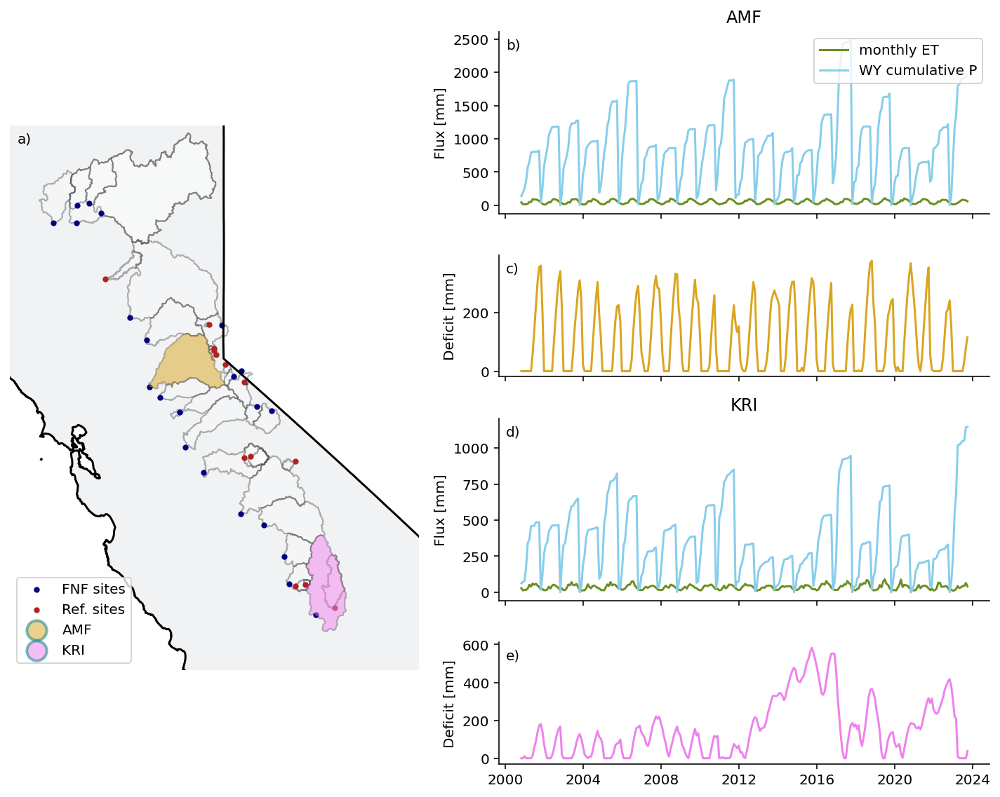

In [18]:
# make site figure

def set_shortname(staname):
    staname = staname.split(' ')
    if staname[0]=='SAN':
        return ' '.join(staname[:2])+' RIVER'
    elif staname[0]=='ROCK':
        return 'ROCK CREEK'
    else:
        return staname[0]+' RIVER'
plotid = ['AMF','KRI',]#'FTO','TRF','10336676']
fig = plt.figure(figsize = (10,8), tight_layout=True)
gs = GridSpec(4,2, width_ratios=[1,1.2],height_ratios = [1.5,1,1.5,1])
axmap = fig.add_subplot(gs[:,0])
axs = [fig.add_subplot(gs[i,1]) for i in range(4)]

ax = axmap
gages['shortname'] = gages.STANAME.apply(set_shortname)
gages.to_crs('EPSG:3857').plot(edgecolor = 'k',facecolor = 'white',alpha=.3,#cmap='tab20b',#cmap='Set2',
                               ax = ax,#legend=True,
           legend_kwds={'bbox_to_anchor':(.55,.6),#.75,0.3),
                        'loc':'lower left',
                       'ncol':2})
state_outline.to_crs('EPSG:3857').plot(ax=ax,facecolor='slategrey',zorder=-1,alpha=.1)
state_outline.to_crs('EPSG:3857').boundary.plot(ax=ax,edgecolor='k')
ax.axis('off')
gages1 = gpd.GeoDataFrame(gages[['LATITUDE','LONGITUDE_']], 
                          geometry = gpd.points_from_xy(gages.LONGITUDE_, 
                                                        gages.LATITUDE)).set_crs('EPSG:4326').to_crs('EPSG:3857')

casites1 = casites1.to_crs('EPSG:3857')
ax.scatter(gages1.geometry.x, gages1.geometry.y, c='navy', s = 10,label='FNF sites')
ax.scatter(casites1.geometry.x, casites1.geometry.y, c='firebrick',s=10,label='Ref. sites')
ax.set_ylim(4.15e6,5.15e6)
colors = ['goldenrod','violet','skyblue','slateblue','yellowgreen']
for i,ID in enumerate(plotid):
    gages[gages.STAID==ID].to_crs('EPSG:3857').plot(facecolor = colors[i],ax=ax,label=None,#label=ID,
                                                   zorder = 1000,alpha=.5)
    ax.scatter([-100,],[-100],c=colors[i],label=ID,edgecolor = 'teal',lw=2,alpha=.5,s=200)
ax.legend(loc='lower left')
ax.set_xlim(-1.375e7,-1.3e7)
colors = ['goldenrod','violet']

for j,id in enumerate(['AMF','KRI']):
    ax = axs[j*2]
    dd = data1[id]
    dd['WY'] = np.where(dd.index.month>=10,dd.index.year+1,dd.index.year)
    ddc = [0]
    ddet = [0]
    wy = dd.WY.values[0]
    for i in range(len(dd)):
      if dd.WY.values[i]==wy:
        ddc.append(ddc[-1]+dd.P.values[i])
        ddet.append(ddet[-1]+dd.D.values[i])
      else:
        ddc.append(dd.P.values[i])
        ddet.append(dd.ET.values[i])
        wy = dd.WY.values[i]
    ax.plot(dd.index,dd.ET,c='olivedrab',label='monthly ET',)
    ax.plot(dd.index,ddc[1:],c='skyblue',label='WY cumulative P')
    if j==0:
        ax.legend(loc = 'upper right')
    ax.set_xticklabels([])
    ax.spines[['top','right']].set_visible(False)
    ax.set_ylabel('Flux [mm]')
    ax.set_title(id,)

    ax = axs[j*2+1]
    ax.plot(dd.D,c=colors[j])
    if j==0:
      ax.set_xticklabels([])
    ax.spines[['top','right']].set_visible(False)
    ax.set_ylabel('Deficit [mm]')

labels = ['a)','b)','c)','d)','e)']
for j,ax in enumerate([axmap]+axs):
    ax.annotate(
        labels[j],
        xy=(0, 1), xycoords='axes fraction',
        xytext=(+0.5, -0.5), textcoords='offset fontsize',
         verticalalignment='top', )

# plt.savefig('../Figures/sitemap.png',dpi=300,format='png',bbox_inches='tight')

# Import Data

In [20]:
data1 = {}
for key in gages.STAID.values:
  print(key)
  d = pd.read_csv('../Data/SWANN/'+str(key)+'_data_SWANN.csv')
  d['Unnamed: 0'] = pd.to_datetime(d['Unnamed: 0'])
  d = d.set_index('Unnamed: 0')
  data1[key] = d

TNL
SIS
SDT
MSS
PSH
FTO
YRS
AMF
CSN
MKM
SNS
MRC
TRF
WFC
SBF
EFC
WWR
KGF
EWR
KWT
SCC
KRI
10336780
10336645
10336660
10336676
10343500
10308783
11383500
11189500
11204100
11203580
11266500
11264500
10265150


In [21]:
# functions to import joblib data
def import_Dpix(key):
  d = joblib.load('../Data/joblib_files/'+str(key)+'_Dpix.joblib').reset_index()
  d = d.set_index('date')
  return d

def import_Qpix(key):
  d = joblib.load('../Data/joblib_files/'+str(key)+'_Qpix.joblib').reset_index()
  d = d.set_index('date')
  return d

def import_arrays(key):
  d = joblib.load('../Data/joblib_files/'+str(key)+'_arrays.joblib').reset_index()
  d.set_index('index',inplace=True)
  return d

def import_arrays_wy(key):
  d = joblib.load('../Data/joblib_files/'+str(key)+'_arrays_wy.joblib').reset_index()
  d.set_index('index',inplace=True)
  return d

def import_arrays_monthly(key):
  d = joblib.load('../Data/joblib_files/'+str(key)+'_arrays_monthly.joblib').reset_index()
  d.set_index('index',inplace=True)
  return d

In [32]:
# calculate stuff for plots

q25dict = {}
q75dict = {}
q50dict = {}
Ddict = {}
indexdict = {}
pixg0dict = {}
pixg00dict = {}
MAEvals = {}
hplotdict = {}
stdevdict = {}

for j, key in enumerate(list(gages.STAID.values)[:]):
  # ax = axs[j]
  print(key)
  d = import_Dpix(key)
  ddd = d[d.index=='9-30-2021'].DpixArray.values[0]
  mask = (ddd>2000)

  hplot = []
  Dvals = []
  rmsevals = []
  q25vals = []
  q75vals = []
  q50vals = []
  stdevvals = []
  pixg0 = []
  pixg00 = []

  for i in range(len(d)):
    dd = d.DpixArray.values[i]
    dd = np.where((dd>np.nanmedian(dd)*4)&(dd>200),np.nan,dd)# mask out runaway deficit pixels
    hvals = dd.flatten()
    hvals = np.where(np.isnan(hvals),-100,hvals)

    hh, bin = np.histogram(hvals,bins = np.linspace(0,800,30))
    hplot.append(hh)
    df = pd.DataFrame.from_dict({'vals':hvals})
    df = df[df.vals>=0]
    q25vals.append(df.quantile(.25).values[0])
    q75vals.append(df.quantile(.75).values[0])
    q50vals.append(df.quantile(.50).values[0])
    stdevvals.append(df.std().values[0])

    try:

      Dvals.append(data1[key].loc[d.index.values[i]].D)
    except:
      Dvals.append(np.nan)
    try:
      pixg0.append(len(df[df.vals>Dvals[-1]*1.1])/len(df)*100)
    except:
      pixg0.append(np.nan)
    try:
      pixg00.append(len(df[df.vals>Dvals[-1]+10])/len(df)*100)
    except:
      pixg00.append(np.nan)
    try:
      rmsevals.append((np.mean(abs(df.vals-Dvals[-1]))))

    except:
      rmsevals.append(np.nan)
      # continue
  hplot = np.transpose(np.array(hplot))

  hplot = hplot/len(df)*100
  hplotdict[key] = hplot
  q25dict[key] = q25vals
  q75dict[key] = q75vals
  q50dict[key] = q50vals
  Ddict[key] = Dvals
  indexdict[key] = d.index
  MAEvals[key] = rmsevals
  pixg0dict[key] = pixg0
  pixg00dict[key] = pixg00
  stdevdict[key] = stdevvals



TNL
SIS
SDT
MSS
PSH
FTO
YRS
AMF
CSN
MKM
SNS
MRC
TRF
WFC
SBF
EFC
WWR
KGF
EWR
KWT
SCC
KRI
10336780
10336645
10336660
10336676
10343500
10308783
11383500
11189500
11204100
11203580
11266500
11264500
10265150


# Look at pixel v basin deficit results

(np.float64(-123.29185298466882),
 np.float64(-117.72794687869131),
 np.float64(35.0975008260412),
 np.float64(42.148129695028096))

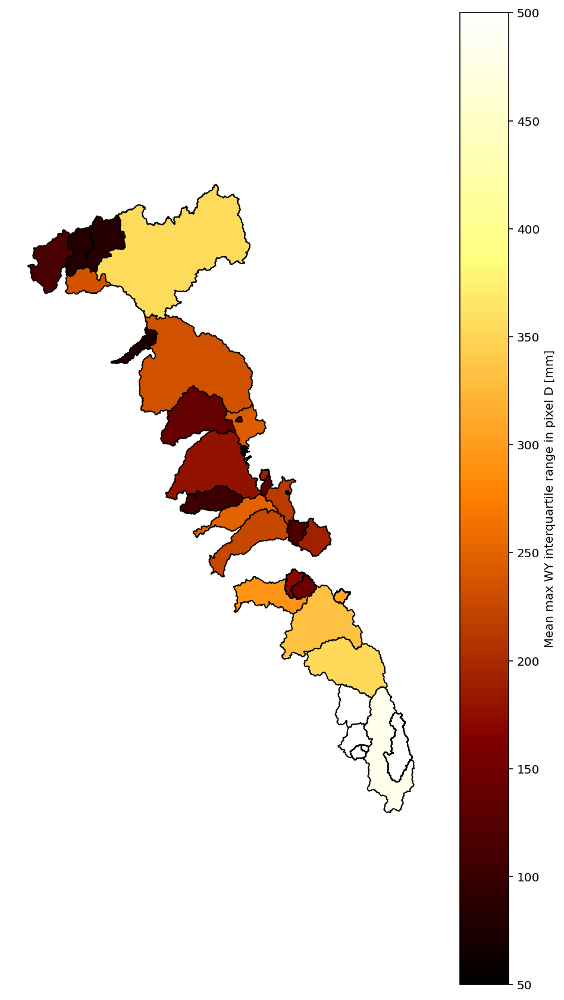

In [34]:

qds = []
for key in gages.STAID:
    dindex = indexdict[key]
    q25 = q25dict[key]
    q75 = q75dict[key]
    quantiledict = pd.DataFrame.from_dict({'date':dindex,
                                          'q25':q25,
                                          'q75':q75})
    quantiledict.set_index('date',inplace=True)
    quantiledict['wy'] = np.where(quantiledict.index.month>=10,quantiledict.index.year+1,
                                 quantiledict.index.year)
    quantiledict['qrange'] = quantiledict.q75-quantiledict.q25
    quantiledict1 = quantiledict.groupby('wy').max()
    qds.append(quantiledict1.qrange.mean())
qd = pd.DataFrame.from_dict({'STAID':gages.STAID.values,
                            'qd':qds})
Correlations = pd.read_csv('../Data/Correlations/Correlations_SWANN_dwr.csv')
fig,ax = plt.subplots(1,figsize = (8,15))
mmap = gages[['STAID','geometry']].merge(qd,#Correlations[['basin','D_var']].rename(columns={'basin':'STAID'}).groupby('STAID').mean().reset_index(),
                                 on='STAID')
mmap.plot(column='qd',legend=True,vmin = 50,vmax = 500, ax=ax,cmap='afmhot',edgecolor = 'k',
         legend_kwds={'label':'Mean max WY interquartile range in pixel D [mm]',
#                      'orientation':'horizontal'
                     })
ax.axis('off')

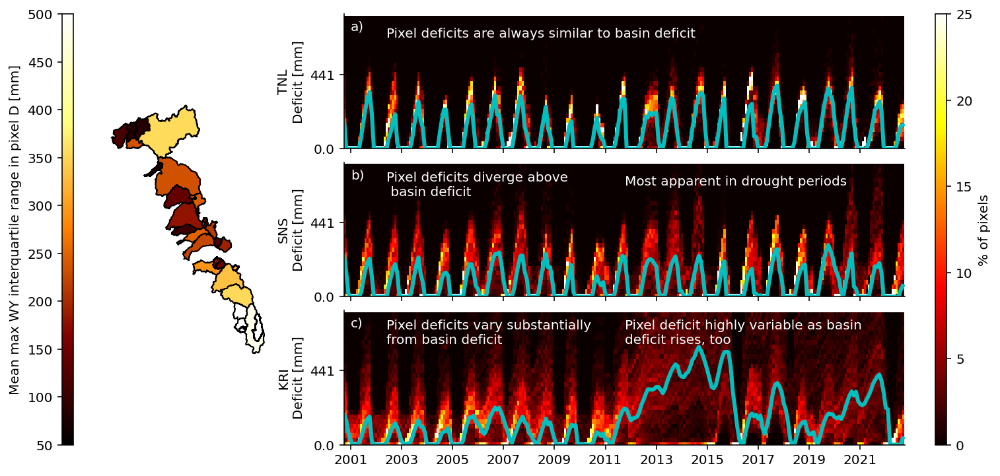

In [35]:
plotgages = ['TNL','SNS','KRI',]#cabasins.STAID.values[8]]


fig = plt.figure(figsize = (12,2*len(plotgages)), )#tight_layout=True)
gs = GridSpec(len(plotgages),5, width_ratios=[1,15,1,50,1],height_ratios=[1,1,1])
axmap = fig.add_subplot(gs[:,1])
cax1 = fig.add_subplot(gs[:,0])
axs = [fig.add_subplot(gs[i,3]) for i in range(len(plotgages))]
cax = fig.add_subplot(gs[:,4])


ax = axmap
mmap = gages[['STAID','geometry']].merge(qd,on='STAID')
mmap.plot(column='qd',legend=True,vmin = 50,vmax = 500, ax=ax,cmap='afmhot',edgecolor = 'k',
         legend_kwds={'label':'Mean max WY interquartile range in pixel D [mm]','cax':cax1,
                     })
ax.axis('off')
cax1.yaxis.set_label_position('left')
cax1.yaxis.set_ticks_position('left')

for j, key in enumerate(plotgages):
  ax = axs[j]
  hplot = hplotdict[key]
  Dvals = Ddict[key]


  im = ax.imshow(hplot, cmap='hot',vmin = 0, vmax = 25,aspect='auto' )
  ax.set_ylim(0,len(hh))
  ax.set_yticks([0,16])
  ax.set_yticklabels([bin[0],round(bin[16])])
  ax.spines[['top','right']].set_visible(False)
  ax.set_ylabel(key+'\nDeficit [mm]')
  ax.set_xticks([i*24+3 for i in range(11)])
  ax.set_xticklabels([2001+i*2 for i in range(11)])
  ax.set_xlim(0,len(hplot[0]))


  ax.plot((Dvals/(bin[1]-bin[0])),c='c',lw=3)

  if j<len(plotgages)-1:
    ax.set_xticklabels([])

cbar = plt.colorbar(im, cax = cax)
cax.set_ylabel('% of pixels')
plt.subplots_adjust(hspace=.1)
# fig.tight_layout()

labels = ['a)','b)','c)','d)','e)','f)','g)','h)','i)']*4
for j,ax in enumerate(axs):
    ax.annotate(
        labels[j],
        xy=(0, 1), xycoords='axes fraction',
        xytext=(+0.5, -0.5), textcoords='offset fontsize',
         verticalalignment='top', c='white')
    
fs = 10
ax = axs[0]
ax.text(20,24,'Pixel deficits are always similar to basin deficit',c='white',fontsize = fs)
ax = axs[1]
ax.text(20,27,'Pixel deficits diverge above\n basin deficit',c='white',fontsize = fs,va='top')
ax.text(12*11,24,'Most apparent in drought periods',c='white',fontsize = fs)
ax = axs[2]
ax.text(20,27,'Pixel deficits vary substantially\nfrom basin deficit',c='white',fontsize = fs,va='top')
ax.text(12*11,27,'Pixel deficit highly variable as basin\ndeficit rises, too',c='white',fontsize = fs,
       va = 'top')

plt.savefig('deficit_heatmaps.png',format='png',dpi=300,bbox_inches='tight')




In [36]:
plotgages = gages.STAID.values
fig = plt.figure(figsize = (14,2*len(plotgages)), tight_layout=True)
gs = GridSpec(len(plotgages),4, width_ratios = [12,12,12,1])
axs = [fig.add_subplot(gs[i,0]) for i in range(len(plotgages))]
axs1 = [fig.add_subplot(gs[i,1]) for i in range(len(plotgages))]
axs2 = [fig.add_subplot(gs[i,2]) for i in range(len(plotgages))]

axs = [axs,axs1,axs2,]#axs3]
caxs = [fig.add_subplot(gs[i,3]) for i in range(len(plotgages))]
cmap_use = 'magma'

for j, key in enumerate(list(plotgages)[:]):

  d = import_Dpix(key)
  ddd = d[d.index=='9-30-2021'].DpixArray.values[0]
  mask = (ddd>2000)

  for i,date in enumerate([2015,2016,2021]):
    ax = axs[i][j]

    ddd = d[d.index=='9-30-'+str(date)].DpixArray.values[0]
    mask = (ddd>np.nanmedian(ddd)*4)&(ddd>200)
    im = ax.imshow(np.where(mask,np.nan,ddd),
                   vmin = 0, vmax = d.Dpixel.max()*1.5, cmap = cmap_use)
    ax.spines[['top','right','bottom','left']].set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])
    if j==0:
      ax.set_title('Oct. '+str(date)+'\n\n')
    if i==0:
      ax.set_ylabel(key,fontsize = 11)
  cbar = plt.colorbar(im, cax = caxs[j])
  caxs[j].set_ylabel('Deficit [mm]')

fig.tight_layout()


In [41]:
# import correlation matrices for all sites and years
Correlations = pd.read_csv('../Data/Correlations/Correlations_SWANN_allsites.csv')
Correlations.drop(columns='Unnamed: 0',inplace=True)

In [43]:
# import elevation rasters for each site
elevations = joblib.load('../Data/joblib_files/DWR_basins_elevation.joblib')
elevations = pd.concat([elevations, joblib.load('../Data/joblib_files/cabasins_elevation.joblib')])

In [45]:
# identify locations within watershed of high P, low P, high ET, low ET, high D, low D, etc.

sitecoords = {'STAID':[],
                 'p_xdist':[],
                 'p_ydist':[],
                 'et_xdist':[],
                 'et_ydist':[],
                 'd_xdist':[],
                 'd_ydist':[],
              'lowd_xdist':[],
                 'lowd_ydist':[],
              'q_xdist':[],
              'q_ydist':[],
              'q_elev':[],
             'p_elev':[],
             'et_elev':[],
             'd_elev':[],
              'lowd_elev':[],
             'outlet_elev':[],
             'max_elev':[]}

for i in range(len(gages)):
    print(i,'of',len(gages))
    year = 2021
    key = gages.STAID.values[i]

    

    ars = import_arrays_wy(key)
    ars['year'] = list(range(2001,2024))
    ars.set_index('year',inplace=True)

    pp = ars[ars.index==(year)].Parray.values[0]
    etet = ars[ars.index==(year)].ETarray.values[0]
    d = import_Dpix(key)
    ddd = d[d.index=='9-30-2021'].DpixArray.values[0]
    mask = (ddd>np.nanmedian(ddd*4))&(ddd>200)
    maxD = min([1000,d.Dpixel.max()*1.5])
    d = d[d.index=='9-30-'+str(year)].DpixArray.values[0]
    d = np.where(mask,np.nan,d)
    
    qpixdata = import_Qpix(key)
    qpixdata['wy'] = np.where(qpixdata.index.month>=10,qpixdata.index.year+1,qpixdata.index.year)
    wynum = len(qpixdata.wy.unique())
    qpixdata = qpixdata[['QpixArray']].sum()/wynum
    q = qpixdata.values[0]

    arr = elevations[elevations.STAID==key].elevation.values[0]
    arr = np.where(np.isnan(arr),np.nanmax(arr),arr)
    # np.argmax(np.where(arr==np.nanmin(arr),1,np.nan))
    row = int(np.argmin(arr)/len(arr[0]))
    col = int(np.argmin(arr))-row*len(arr[0])

    xval = np.array([[[i] for i in range(len(etet[0]))] for j in range(len(etet))])
    yval = np.array([[[j] for i in range(len(etet[0]))] for j in range(len(etet))])

    dhigh_x = np.where(d>=np.nanpercentile(d,75),xval,np.nan)
    dhigh_y = np.where(d>=np.nanpercentile(d,75),yval,np.nan)
    dcoords = pd.DataFrame.from_dict({'x':dhigh_x.flatten(),
                                    'y':dhigh_y.flatten()}).dropna()
    dlow_x = np.where(d<=np.nanpercentile(d,25),xval,np.nan)
    dlow_y = np.where(d<=np.nanpercentile(d,25),yval,np.nan)
    dlowcoords = pd.DataFrame.from_dict({'x':dlow_x.flatten(),
                                    'y':dlow_y.flatten()}).dropna()
    
    qhigh_x = np.where(q>=np.nanpercentile(q,75),xval,np.nan)
    qhigh_y = np.where(q>=np.nanpercentile(q,75),yval,np.nan)
    qcoords = pd.DataFrame.from_dict({'x':qhigh_x.flatten(),
                                    'y':qhigh_y.flatten()}).dropna()

    ethigh_x = np.where(etet>=np.nanpercentile(etet,75),xval,np.nan)
    ethigh_y = np.where(etet>=np.nanpercentile(etet,75),yval,np.nan)
    etcoords = pd.DataFrame.from_dict({'x':ethigh_x.flatten(),
                                    'y':ethigh_y.flatten()}).dropna()

    plow_x = np.where(pp<=np.nanpercentile(pp,25),xval,np.nan)
    plow_y = np.where(pp<=np.nanpercentile(pp,25),yval,np.nan)
    pcoords = pd.DataFrame.from_dict({'x':plow_x.flatten(),
                                    'y':plow_y.flatten()}).dropna()

    xdist = abs(xval - col)
    ydist = abs(yval - row)
    p_xdist = abs(pcoords.x.mean()-col)/np.nanmax(xdist)
    et_xdist = abs(etcoords.x.mean()-col)/np.nanmax(xdist)
    d_xdist = abs(dcoords.x.mean()-col)/np.nanmax(xdist)
    lowd_xdist = abs(dlowcoords.x.mean()-col)/np.nanmax(xdist)
    q_xdist = abs(qcoords.x.mean()-col)/np.nanmax(xdist)
    p_ydist = abs(pcoords.y.mean()-row)/np.nanmax(ydist)
    et_ydist = abs(etcoords.y.mean()-row)/np.nanmax(ydist)
    d_ydist = abs(dcoords.y.mean()-row)/np.nanmax(ydist)
    lowd_ydist = abs(dlowcoords.y.mean()-row)/np.nanmax(ydist)
    q_ydist = abs(qcoords.y.mean()-row)/np.nanmax(ydist)
    
    outlet_elev = float(arr[row][col])
    max_elev = float(np.nanmax(arr))
    et_elev = float(arr[round(etcoords.y.mean())][round(etcoords.x.mean())])
    p_elev = float(arr[round(pcoords.y.mean())][round(pcoords.x.mean())])
    d_elev = float(arr[round(dcoords.y.mean())][round(dcoords.x.mean())])
    lowd_elev = float(arr[round(dlowcoords.y.mean())][round(dlowcoords.x.mean())])
    q_elev = float(arr[round(qcoords.y.mean())][round(qcoords.x.mean())])

    sitecoords['STAID'].append(key)
    sitecoords['p_xdist'].append(p_xdist)
    sitecoords['et_xdist'].append(et_xdist)
    sitecoords['d_xdist'].append(d_xdist)
    sitecoords['lowd_xdist'].append(lowd_xdist)
    sitecoords['q_xdist'].append(q_xdist)
    sitecoords['p_ydist'].append(p_ydist)
    sitecoords['et_ydist'].append(et_ydist)
    sitecoords['d_ydist'].append(d_ydist)
    sitecoords['lowd_ydist'].append(lowd_ydist)
    sitecoords['q_ydist'].append(q_ydist)
    sitecoords['p_elev'].append(p_elev)
    sitecoords['lowd_elev'].append(lowd_elev)
    sitecoords['d_elev'].append(d_elev)
    sitecoords['q_elev'].append(q_elev)
    sitecoords['et_elev'].append(et_elev)
    sitecoords['outlet_elev'].append(outlet_elev)
    sitecoords['max_elev'].append(max_elev)

sitecoords = pd.DataFrame.from_dict(sitecoords)

sitecoords['relp'] = (sitecoords.p_elev-sitecoords.outlet_elev)/(sitecoords.max_elev-sitecoords.outlet_elev)
sitecoords['relet'] = (sitecoords.et_elev-sitecoords.outlet_elev)/(sitecoords.max_elev-sitecoords.outlet_elev)
sitecoords['reld'] = (sitecoords.d_elev-sitecoords.outlet_elev)/(sitecoords.max_elev-sitecoords.outlet_elev)
sitecoords['relq'] = (sitecoords.q_elev-sitecoords.outlet_elev)/(sitecoords.max_elev-sitecoords.outlet_elev)

sitecoords['outp'] = sitecoords.p_elev-sitecoords.outlet_elev
sitecoords['outet'] = sitecoords.et_elev-sitecoords.outlet_elev
sitecoords['outd'] = sitecoords.d_elev-sitecoords.outlet_elev

0 of 35
1 of 35
2 of 35
3 of 35
4 of 35
5 of 35
6 of 35
7 of 35
8 of 35
9 of 35
10 of 35
11 of 35
12 of 35
13 of 35
14 of 35
15 of 35
16 of 35
17 of 35
18 of 35
19 of 35
20 of 35
21 of 35
22 of 35
23 of 35
24 of 35
25 of 35
26 of 35
27 of 35
28 of 35
29 of 35
30 of 35
31 of 35
32 of 35
33 of 35
34 of 35


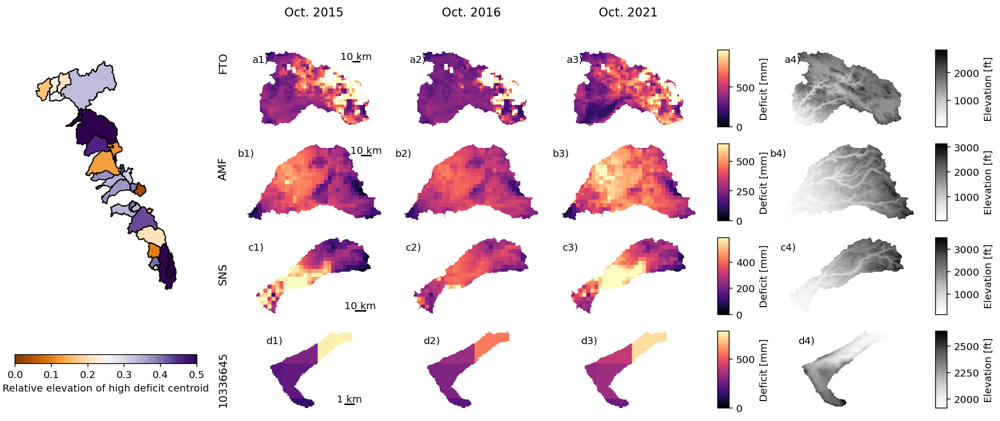

In [49]:
plotgages = ['FTO','AMF','SNS',cabasins.STAID.values[8],]
fig = plt.figure(figsize = (14,1.5*len(plotgages)), tight_layout=True)
gs = GridSpec(len(plotgages),9, width_ratios = [16,.6,12,12,12,1,.6,12,1])
axs = [fig.add_subplot(gs[i,2]) for i in range(len(plotgages))]
axs1 = [fig.add_subplot(gs[i,3]) for i in range(len(plotgages))]
axs2 = [fig.add_subplot(gs[i,4]) for i in range(len(plotgages))]
axs3 = [fig.add_subplot(gs[i,7]) for i in range(len(plotgages))]
axmap = fig.add_subplot(gs[:,0])
axs = [axs,axs1,axs2,axs3]
caxs = [fig.add_subplot(gs[i,5]) for i in range(len(plotgages))]
caxs1 = [fig.add_subplot(gs[i,8]) for i in range(len(plotgages))]
cmap_use = 'magma'


ax = axmap
gages[['STAID','geometry']].merge(sitecoords[['STAID','reld']],on='STAID').plot(column='reld',
                                                                               cmap = 'PuOr',vmin=0,vmax=.5,
                                                                               legend=True,
                                                                                legend_kwds = {'orientation':'horizontal',
                                                                                               'label':'Relative elevation of high deficit centroid'},
                                                                               edgecolor = 'k',
                                                                               ax = ax)
ax.axis('off')

ypos = [.15,.15,.95,.95
         ]
xpos = [.85]*4#,.9,.9,.9
#          ]
#   textpos = []
scalesize = [100,100,100,10]

for j, key in enumerate(list(plotgages)[:]):

  d = import_Dpix(key)
  ddd = d[d.index=='9-30-2021'].DpixArray.values[0]
  mask = (ddd>2000)

  ax = axs[-1][j]
  elev = elevations[elevations.STAID==key].elevation.values[0]
  ii = ax.imshow(elev,cmap='Greys',)
  plt.colorbar(ii,cax=caxs1[j],)#orientation='horizontal')
  caxs1[j].set_ylabel('Elevation [ft]')
  ax.axis('off')

  for i,date in enumerate([2015,2016,2021]):
    ax = axs[i][j]
    

    ddd = d[d.index=='9-30-'+str(date)].DpixArray.values[0]
    mask = (ddd>np.nanmedian(ddd)*4)&(ddd>200)
    im = ax.imshow(np.where(mask,np.nan,ddd),
                   vmin = 0, vmax = d.Dpixel.max()*1.5, cmap = cmap_use)
    ax.spines[['top','right','bottom','left']].set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])
    
    if date==2015:
        ar = ddd
        ax.plot([int(len(ar[0])*xpos[j]),int(len(ar[0])*xpos[j])+scalesize[j]],[int(len(ar)*ypos[j])]*2,c='k')
        ax.text(int(len(ar[0])*xpos[j])+scalesize[j]/2,int(len(ar)*(ypos[j])),
                str(int(scalesize[j]/10))+' km',ha='center',va = 'bottom')
    
    if j==0:
      ax.set_title('Oct. '+str(date)+'\n\n')
    if i==0:
      ax.set_ylabel(key,fontsize = 11)
      ax.get_yaxis().set_label_coords(0.23,-.14+0.245*(len(plotgages)-j), transform = fig.transFigure)

  cbar = plt.colorbar(im, cax = caxs[j])
  caxs[j].set_ylabel('Deficit [mm]')


fig.tight_layout()
plt.subplots_adjust(wspace=.25,)
# fig.align_ylabels()

labels = ['a)','b)','c)','d)','e)','f)','g)','h)','i)']*4
for j,ax in enumerate(axs[0]):
    ax.annotate(
        labels[j][:-1]+'1)',
        xy=(-.1, 1), xycoords='axes fraction',
        xytext=(+0.5, -0.5), textcoords='offset fontsize',
         verticalalignment='top', c='k')
    axs[1][j].annotate(
        labels[j][:-1]+'2)',
        xy=(-.10, 1), xycoords='axes fraction',
        xytext=(+0.5, -0.5), textcoords='offset fontsize',
         verticalalignment='top', c='k')
    axs[2][j].annotate(
        labels[j][:-1]+'3)',
        xy=(-.10, 1), xycoords='axes fraction',
        xytext=(+0.5, -0.5), textcoords='offset fontsize',
         verticalalignment='top', c='k')
    axs[3][j].annotate(
        labels[j][:-1]+'4)',
        xy=(-.10, 1), xycoords='axes fraction',
        xytext=(+0.5, -0.5), textcoords='offset fontsize',
         verticalalignment='top', c='k')

plt.savefig('deficit_pixel_maps.png',format='png',dpi=300,bbox_inches='tight')

In [52]:
# cluster basins by deficit behavior
from sklearn.cluster import KMeans
from sklearn import metrics

cols = ['D_P','D_ET',#'P_ET',
                    'relp','relet','reld',
#                      'outp','outet','outd',
                    ]
clusterdf = sitecoords.copy()
scores = []
for i in range(2,len(clusterdf)-1):
    Correlations1 = Correlations.copy()
    Correlations1['basin'] = Correlations1.basin.astype('str')
    clusterdf = Correlations1.groupby('basin').median()[['D_P','D_ET','P_ET']].reset_index().rename(columns={'basin':'STAID'}).merge(sitecoords,on='STAID')
    kmean = KMeans(n_clusters = i+1, random_state = 42, n_init = 3)
    kmean.fit(clusterdf[cols])
    labels = kmean.labels_
    clusterdf['cluster'] = kmean.labels_
    scores.append(metrics.silhouette_score(clusterdf[cols],labels,metric='euclidean'))
numcluster = 4#np.argmax(scores)+2
kmean = KMeans(n_clusters = numcluster, random_state = 42, n_init = 3)
kmean.fit(clusterdf[cols])
clusterdf['cluster'] = kmean.labels_

cluster 0


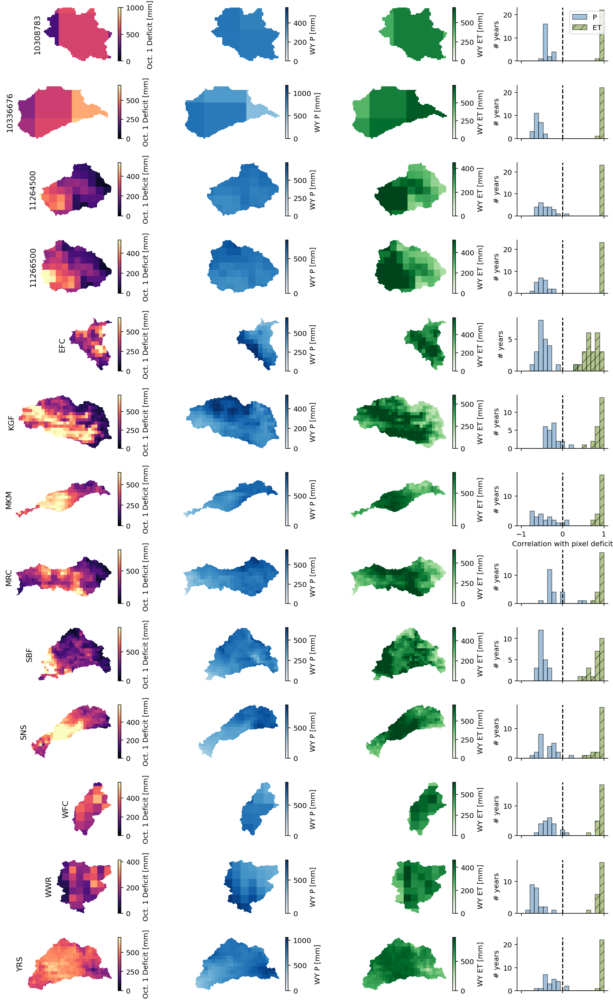


cluster 1


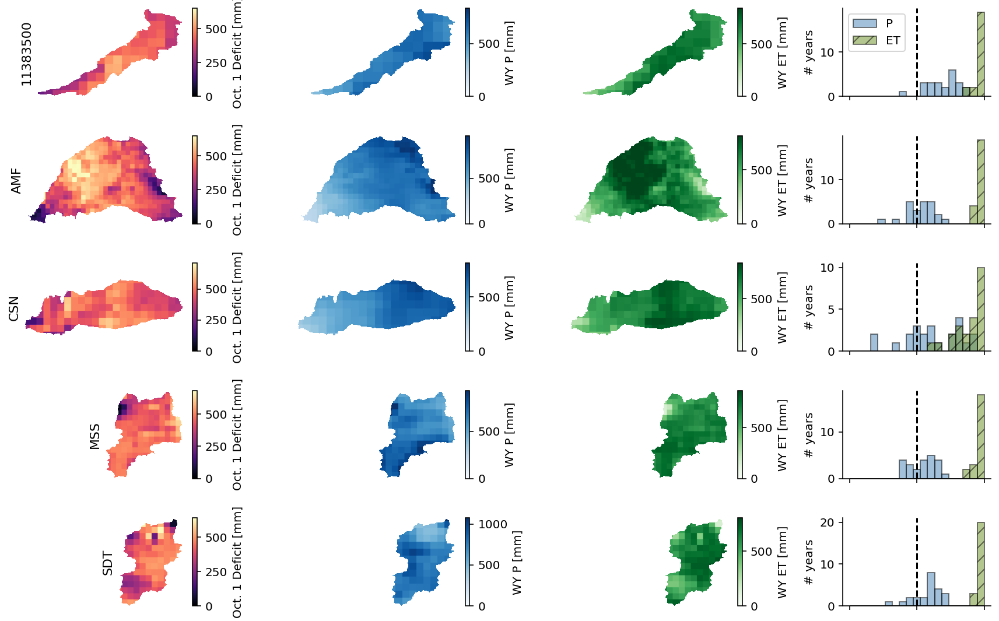


cluster 2


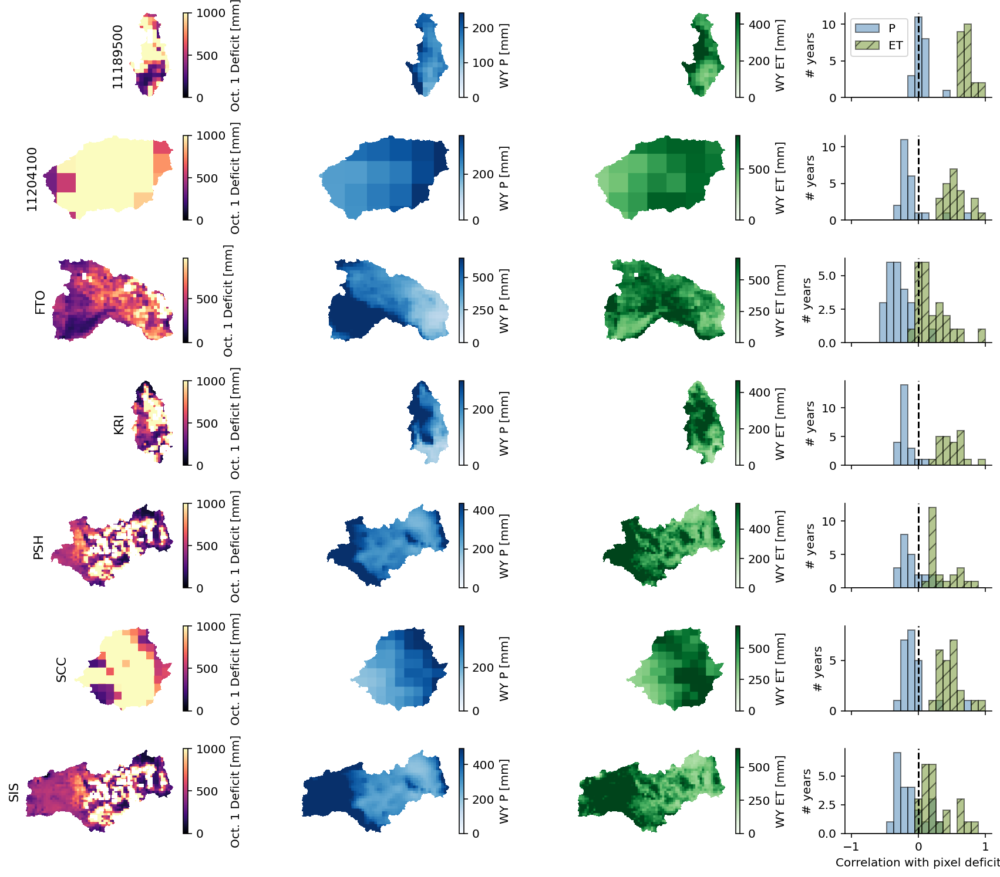


cluster 3


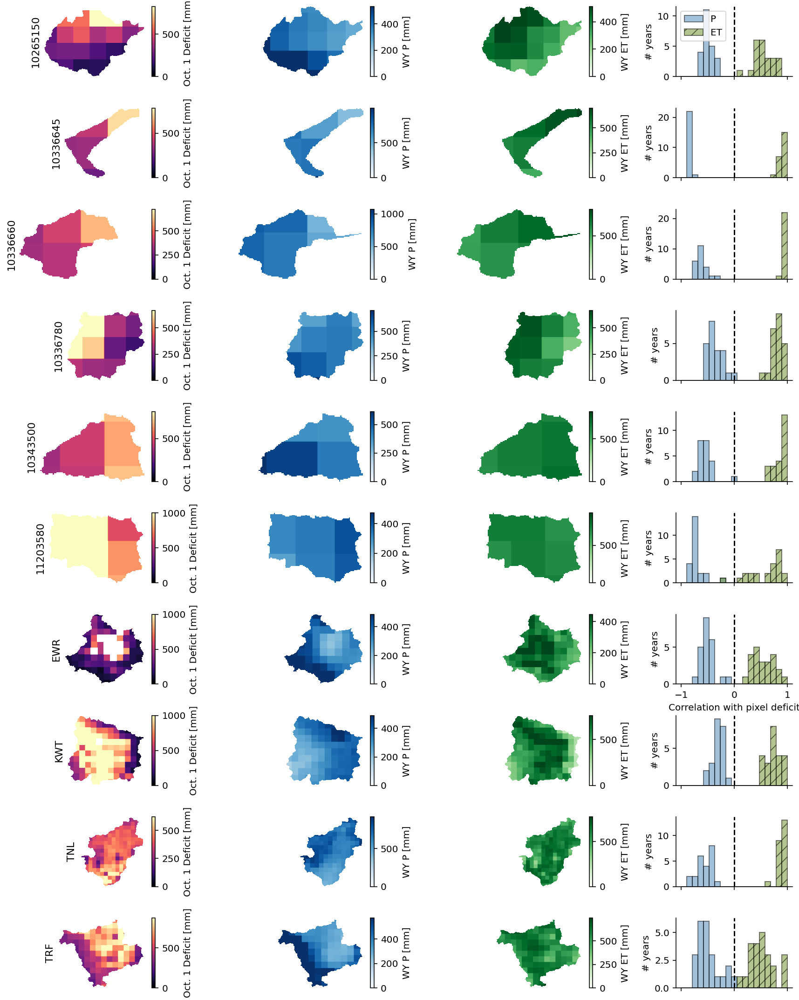

In [53]:

for clust in range(len(clusterdf.cluster.unique())):
    print('cluster',clust)
    plotgages = clusterdf[clusterdf.cluster==clust].STAID.values

    for year in [2021]:

      fig = plt.figure(figsize = (12,1.5*len(plotgages)), tight_layout=True)
      gs = GridSpec(len(plotgages),4, width_ratios = [12,12,12,9])
      axs = [fig.add_subplot(gs[i,0]) for i in range(len(plotgages))]
      axs1 = [fig.add_subplot(gs[i,1]) for i in range(len(plotgages))]
      axs2 = [fig.add_subplot(gs[i,2]) for i in range(len(plotgages))]
      axs3 = [fig.add_subplot(gs[i,3]) for i in range(len(plotgages))]
      axs = [axs,axs1,axs2,]
      cmap_use = 'magma'

      cmaps = [cmap_use,'Blues','Greens']
      barlabels = ['Oct. 1 Deficit [mm]','WY P [mm]','WY ET [mm]']

      for j, key in enumerate(plotgages):

        d = import_Dpix(key)
        ddd = d[d.index=='9-30-2021'].DpixArray.values[0]
        mask = (ddd>np.nanmedian(ddd*4))&(ddd>200)
        maxD = min([1000,d.Dpixel.max()*1.5])
        d = d[d.index=='9-30-'+str(year)].DpixArray.values[0]
        d = np.where(mask,np.nan,d)
        ars = import_arrays_wy(key)
        ars['year'] = list(range(2001,2024))
        ars.set_index('year',inplace=True)

        pp = ars[ars.index==(year)].Parray.values[0]
        etet = ars[ars.index==(year)].ETarray.values[0]

        mults = [1,1.4,1.25]

        for i,ar in enumerate([d,pp,etet]):
          ax = axs[i][j]
          if i==0:
            im = ax.imshow(ar,
                          vmin = 0, vmax = maxD, cmap = cmaps[i])
          else:
            im = ax.imshow(ar,
                          vmin = 0, vmax = np.nanmedian(ar)*mults[i],
                           cmap = cmaps[i])
          ax.spines[['top','right','bottom','left']].set_visible(False)
          ax.set_xticks([])
          ax.set_yticks([])

          if i==0:
            ax.set_ylabel(key,fontsize = 11)
          cbar = plt.colorbar(im, ax = ax)
          cbar.set_label(barlabels[i])

        pdata = Correlations[Correlations.basin==key].set_index('year').drop(columns=['basin','P_ET']).sort_index()
        if len(pdata)==0:
            try:
                pdata = Correlations[Correlations.basin==int(key)].set_index('year').drop(columns=['basin','P_ET']).sort_index()
            except:
                pdata = Correlations[Correlations.basin==(key)].set_index('year').drop(columns=['basin','P_ET']).sort_index()

        ax = axs3[j]
        ax.hist(pdata.D_P,facecolor = 'steelblue',edgecolor = 'k',alpha=.5,bins = np.linspace(-1,1,20),label='P')
        ax.hist(pdata.D_ET,facecolor = 'olivedrab',edgecolor = 'k',alpha=.5,bins = np.linspace(-1,1,20),label='ET',
                hatch='//')
        if j==0:
          ax.legend()
        if j==6:
          ax.set_xlabel('Correlation with pixel deficit')
        else:
          ax.set_xticklabels([])
        ax.axvline(0,c='k',ls='--')
        ax.set_ylabel('# years')
        ax.spines[['top','right']].set_visible(False)

      fig.tight_layout()

      plt.subplots_adjust(hspace=.45,)
      plt.savefig('deficit_pixel_maps_'+str(year)+'.png',format='png',dpi=300,bbox_inches='tight')
      plt.show()
    print('')

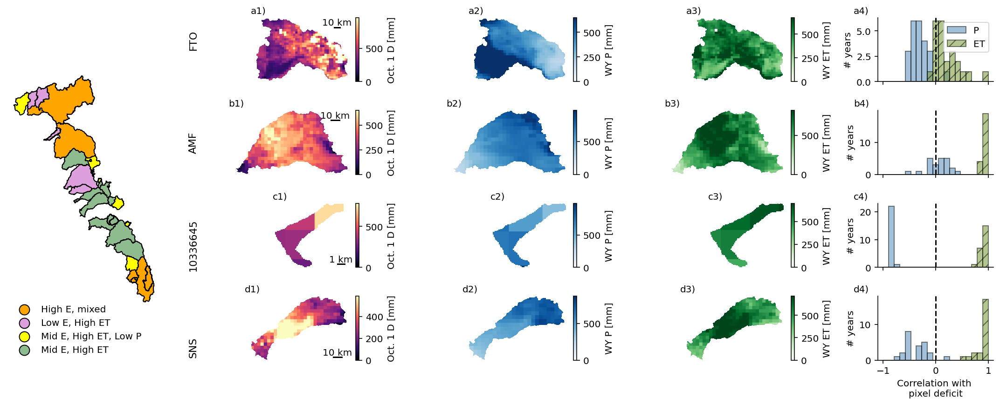

In [54]:
plotgages = ['FTO','AMF',cabasins.STAID.values[8],'SNS']

for year in [2021]:

  fig = plt.figure(figsize = (15,1.5*len(plotgages)), tight_layout=True)
  gs = GridSpec(len(plotgages),5, width_ratios = [12,12,12,12,9])
  axmap = fig.add_subplot(gs[:,0])
  axs = [fig.add_subplot(gs[i,1]) for i in range(len(plotgages))]
  axs1 = [fig.add_subplot(gs[i,2]) for i in range(len(plotgages))]
  axs2 = [fig.add_subplot(gs[i,3]) for i in range(len(plotgages))]
  axs3 = [fig.add_subplot(gs[i,4]) for i in range(len(plotgages))]
  axs = [axs,axs1,axs2,]
  cmap_use = 'magma'

  cmaps = [cmap_use,'Blues','Greens']
  barlabels = ['Oct. 1 D [mm]','WY P [mm]','WY ET [mm]']

    
  ypos = [.15,.15,.95,.95
         ]
  xpos = [.85]*4
  scalesize = [100,100,10,100]
  for j, key in enumerate(plotgages[:]):

    d = import_Dpix(key)
    ddd = d[d.index=='9-30-2021'].DpixArray.values[0]
    mask = (ddd>np.nanmedian(ddd*4))&(ddd>200)
    maxD = min([1000,d.Dpixel.max()*1.5])
    d = d[d.index=='9-30-'+str(year)].DpixArray.values[0]
    d = np.where(mask,np.nan,d)
    ars = import_arrays_wy(key)
    ars['year'] = list(range(2001,2024))
    ars.set_index('year',inplace=True)
    

    pp = ars[ars.index==(year)].Parray.values[0]
    etet = ars[ars.index==(year)].ETarray.values[0]

    mults = [1,1.4,1.25]

    for i,ar in enumerate([d,pp,etet]):
      ax = axs[i][j]
      if i==0:
        im = ax.imshow(ar,
                      vmin = 0, vmax = maxD, cmap = cmaps[i])
        ax.plot([int(len(ar[0])*xpos[j]),int(len(ar[0])*xpos[j])+scalesize[j]],[int(len(ar)*ypos[j])]*2,c='k')
        ax.text(int(len(ar[0])*xpos[j])+scalesize[j]/2,int(len(ar)*(ypos[j])),
                str(int(scalesize[j]/10))+' km',ha='center',va = 'bottom')
      else:
        im = ax.imshow(ar,
                      vmin = 0, vmax = np.nanmedian(ar)*mults[i],
                       cmap = cmaps[i])
      ax.spines[['top','right','bottom','left']].set_visible(False)
      ax.set_xticks([])
      ax.set_yticks([])

      if i==0:
        ax.set_ylabel(key,fontsize = 11)
      ax.get_yaxis().set_label_coords(0.2,-.1+0.255*(len(plotgages)-j), transform = fig.transFigure)

      cbar = plt.colorbar(im, ax = ax)
      cbar.set_label(barlabels[i])

    pdata = Correlations[Correlations.basin==key].set_index('year').drop(columns=['basin','P_ET']).sort_index()
    if len(pdata)==0:
        try:
            pdata = Correlations[Correlations.basin==int(key)].set_index('year').drop(columns=['basin','P_ET']).sort_index()
        except:
            pdata = Correlations[Correlations.basin==(key)].set_index('year').drop(columns=['basin','P_ET']).sort_index()

    ax = axs3[j]
    ax.hist(pdata.D_P,facecolor = 'steelblue',edgecolor = 'k',alpha=.5,bins = np.linspace(-1,1,20),label='P')
    ax.hist(pdata.D_ET,facecolor = 'olivedrab',edgecolor = 'k',alpha=.5,bins = np.linspace(-1,1,20),label='ET',
            hatch='//')
    if j==0:
      ax.legend()
    if j==len(plotgages)-1:
      ax.set_xlabel('Correlation with \npixel deficit')
    else:
      ax.set_xticklabels([])
    ax.axvline(0,c='k',ls='--')
    ax.set_ylabel('# years')
    ax.spines[['top','right']].set_visible(False)


    
  ax = axmap
  withcluster = gages[['STAID','geometry']].merge(clusterdf[['STAID','cluster']],on='STAID')
  colors = {2:'orange',
           0:'darkseagreen',
           1:'plum',
           3:'yellow'}
  clusterlabels={2:'High E, mixed',
                0:'Mid E, High ET',
                1:'Low E, High ET',
                3:'Mid E, High ET, Low P'}
  for cluster in [2,1,3,0]:
    withcluster[withcluster.cluster==cluster].plot(edgecolor = 'k',facecolor = colors[cluster],ax=ax,
                                                  label = clusterlabels[cluster],
#                                                   alpha=.5
                                                  )
    ax.scatter([-120.5],[39.5],c=colors[cluster],
              edgecolor = 'k',label=clusterlabels[cluster],s=120,zorder=-100)
  ax.legend(loc='lower left',frameon=False,bbox_to_anchor = (0,-.2))
  ax.axis('off')
    
  fig.tight_layout()



  labels = ['a)','b)','c)','d)','e)','f)','g)','h)','i)']
  for j,ax in enumerate(axs[0]):
      ax.annotate(
          labels[j][:-1]+'1)',
          xy=(-.1, 1.25), xycoords='axes fraction',
          xytext=(+0.5, -0.5), textcoords='offset fontsize',
          verticalalignment='top', c='k')
      axs[1][j].annotate(
          labels[j][:-1]+'2)',
          xy=(-.10, 1.25), xycoords='axes fraction',
          xytext=(+0.5, -0.5), textcoords='offset fontsize',
          verticalalignment='top', c='k')
      axs[2][j].annotate(
          labels[j][:-1]+'3)',
          xy=(-.10, 1.25), xycoords='axes fraction',
          xytext=(+0.5, -0.5), textcoords='offset fontsize',
          verticalalignment='top', c='k')
      axs3[j].annotate(
          labels[j][:-1]+'4)',
          xy=(-.25, 1.25), xycoords='axes fraction',
          xytext=(+0.5, -0.5), textcoords='offset fontsize',
          verticalalignment='top', c='k')


  # fig.suptitle(year)
  plt.subplots_adjust(hspace=.45,)
  plt.savefig('deficit_pixel_maps_'+str(year)+'.png',format='png',dpi=300,bbox_inches='tight')
  plt.show()


In [55]:
# get statistics on precip data
meanvars = {key:[]
    for key in gages.STAID.values
}
for key in gages.STAID.values[:]:
  ars = import_arrays_wy(key)
  d = import_Dpix(key)
  d = d[(d.index.month==9)|((d.index.month==10)&(d.index.year==2001))]
  vars = []
  varset = []
  varsd = []
  iqd = []
  for i in range(len(ars)):
    pp = ars.Parray.values[i]
    ppet = ars.ETarray.values[i]
    ppd = d.DpixArray.values[i]
    ppd = np.where((ppd>np.nanmedian(ppd)*4)&(ppd>200),np.nan,ppd)
    ppdf = pd.DataFrame.from_dict({'vals':pp.flatten(),
                                   'valset':ppet.flatten(),
                                   'valsd':ppd.flatten()}).dropna()
    vars.append(np.std(ppdf.vals))
    varset.append(np.std(ppdf.valset))
    varsd.append(np.std(ppdf.valsd))
    iqd.append(ppdf.valsd.quantile(.75)-ppdf.valsd.quantile(.25))
  if key==gages.STAID.values[0]:
    vars = vars[:-2]
    varset = varset[:-2]
    varsd = varsd[:-2]
    iqd = iqd[:-2]
  meanvars[key] = [np.mean(vars),np.mean(varset),np.mean(varsd),np.mean(iqd)]

In [56]:
# get drainage area for each basin in km2
def get_drainage(ID):
    if ID in casites.STAID.values:
        return casites[casites.STAID==ID].DRAIN_SQKM.values[0]
    else:
        return gages[gages.STAID==ID].Area_sqkm.values[0]

gages['Area_sqkm'] = [get_drainage(ID) for ID in gages.STAID]

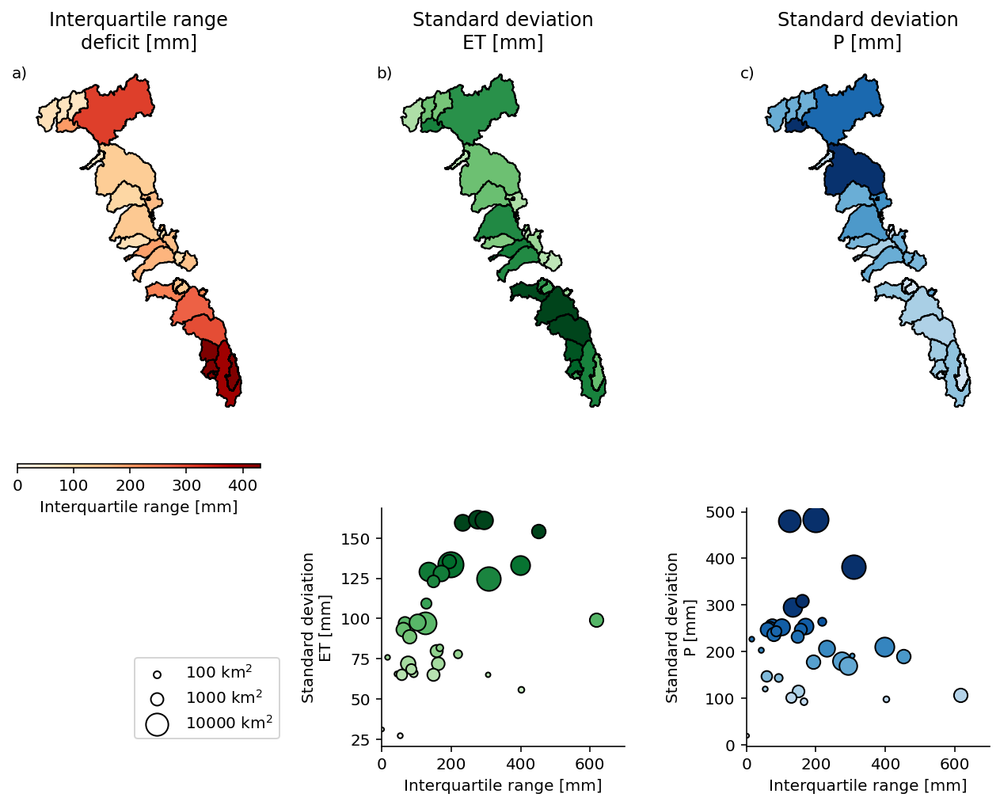

In [57]:
datamerge = pd.DataFrame.from_dict({'STAID':gages.STAID.values,
                                    'ET_std':[meanvars[key][1] for key in gages.STAID.values],
                                    'P_std':[meanvars[key][0] for key in gages.STAID.values],
                                    'D_std':[meanvars[key][2] for key in gages.STAID.values],
                                    'D_MAE':[meanvars[key][3] for key in gages.STAID.values],#np.nanpercentile(MAEvals[key],90) for key in gages.STAID.values]
                                    })
datamerge = gages.merge(datamerge,on='STAID')
datamerge['combo'] = (datamerge.ET_std)/datamerge.ET_std.max()*datamerge.P_std/datamerge.P_std.max()

fig,axs = plt.subplots(3,3,figsize = (11,8),gridspec_kw={'height_ratios':[1,.01,.65]})

ax = axs[0,0]

ylabels = {'D_std':'Standard deviation\ndeficit [mm]',
           'P_std':'Standard deviation\nP [mm]',
           'ET_std':'Standard deviation\nET [mm]',
           'D_MAE':'Interquartile range\ndeficit [mm]'
           }

quant = .9
symbols = ['o',]*100
cmaps = ['OrRd','Greens','Blues','OrRd']
for i,col in enumerate(['D_MAE','ET_std','P_std',]):
  ax = axs[0,i]
  if i==0:
    datamerge.plot(ax=ax,column=col,cmap=cmaps[i],edgecolor = 'k',legend=True,
                   vmin = datamerge[col].min(),
             vmax = datamerge[col].quantile(quant),
              legend_kwds={"label": "Interquartile range [mm]", "orientation": "horizontal",
                           'cax':axs[1,i]}
               )
  else:
    datamerge.plot(ax=ax,column=col,cmap=cmaps[i],edgecolor = 'k',

               )
  ax.set_title(ylabels[col])
  ax.axis('off')

  if i>0:
    ax = axs[1,i]
    ax.axis('off')
  if i==0:
    ax = axs[2,i]
    ax.axis('off')
    continue

  ax = axs[2,i]
  for j,key in enumerate(datamerge.STAID.values):
    ax.scatter([datamerge.D_MAE.values[j]],
            [datamerge[col].values[j]],
            c = datamerge[col].values[j],
             s = (datamerge.Area_sqkm**.5).values[j]*2, 
               edgecolor = 'k',marker = symbols[j],vmin = datamerge[col].min(),
             vmax = datamerge[col].quantile(quant),
             label =None,
             cmap = cmaps[i])
    if key==datamerge.STAID.values[0]:
        for s in [100,1000,10000]:
            ax.scatter([-100],[100],s=s**.5*2,label=str(s)+' km$^2$',edgecolor = 'k',c='white')
    if i==1:
        ax.legend(loc='lower left',bbox_to_anchor = (-1.05,0))
    if i==1:
        corrbasins = Correlations.groupby('basin').D_ET.mean()
        corrbasins = corrbasins[corrbasins<.7]
        corrbasins = corrbasins.index
    if i==2:
        corrbasins = Correlations.groupby('basin').D_P.mean()
        corrbasins = corrbasins[corrbasins>-.1]
        corrbasins = []#corrbasins.index

    ax.set_xlim(0,700)
  ax.set_xlabel('Interquartile range [mm]')#MAE [mm]')
  ax.set_ylabel(ylabels[col])
  ax.spines[['top','right']].set_visible(False)


labels = ['a)','b)','c)','d)','e)','f)','g)']
for j,ax in enumerate(axs[0]):
    ax.annotate(
        labels[j],
        xy=(-.1, 1), xycoords='axes fraction',
        xytext=(+0.5, -0.5), textcoords='offset fontsize',
        verticalalignment='top', c='k')


plt.subplots_adjust(wspace=.5)

plt.savefig('deficit_vary_why.png',format='png',dpi=300,bbox_inches='tight')

# Look at streamflow results

In [58]:
# get a qpixel image for each site
qps = []
qbs = []
for key in gages.STAID.values[:]:
  print(key)
  try:
    qp = import_Qpix(key)
    qp1 = np.mean(qp.QpixArray.values[:])*12
    qps.append(qp1)
    qbs.append(qp.Qpixel)
  except:
    print('fail')

TNL
SIS
SDT
MSS
PSH
FTO
YRS
AMF
CSN
MKM
SNS
MRC
TRF
WFC
SBF
EFC
WWR
KGF
EWR
KWT
SCC
KRI
10336780
10336645
10336660
10336676
10343500
10308783
11383500
11189500
11204100
11203580
11266500
11264500
10265150


In [95]:
# make sure all data is in the dataframe
for i,key in enumerate(gages.STAID.values):
  d = data1[key]
  print(i)
  d['wy'] = np.where(d.index.month>=9,d.index.year+1,d.index.year)

  if 'Dpixel' not in d.columns:
    dpixdata = import_Dpix(key)[['Dpixel']]
    d = d.merge(dpixdata,left_index=True,right_index=True)
    data1[key] = d
  if 'Qpixel' not in d.columns:
    qpixdata = import_Qpix(key).Qpixel
    d = d.merge(qpixdata,left_index=True,right_index=True)
    data1[key] = d

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34


In [94]:
import_Qpix(key).columns

Index(['Qpixel', 'QpixArray'], dtype='object')

In [60]:
# basin = []
# QP_coef = []
# QET_coef = []
# QD_coef = []
# years = []
# qvar = []
# t = time.time()
# for j, key in enumerate(list(gages.STAID.values)[:]):
#   print(j,key)
#   q1 = import_Qpix(key)
#   d1 = import_Dpix(key)
#   q1['year'] = q1.index.year


#   for year in range(2001,2024):
#     if year==2001:
#       d = d1.DpixArray.values[0]
#     else:
#       d = d1[d1.index=='9-30-'+str(year)].DpixArray.values[0]
#     d = np.where((d>np.nanmedian(d)*4)&(d>200),np.nan,d)
#     d = np.array([[d[i][j][0] for j in range(len(d[i]))] for i in range(len(d))])
#     qq = q1[q1.year==year].QpixArray.sum()

#     ars = import_arrays_wy(key)
#     ars['year'] = list(range(2001,2024))
#     ars.set_index('year',inplace=True)
#     pp = ars[ars.index==(year)].Parray.values[0]
#     pp = np.array([[pp[i][j][0] for j in range(len(pp[i]))] for i in range(len(pp))])
#     etet = ars[ars.index==(year)].ETarray.values[0]
#     etet = np.array([[etet[i][j][0] for j in range(len(etet[i]))] for i in range(len(etet))])
#     dfar = pd.DataFrame.from_dict({'Q':qq.flatten(),
#                                 'ET':etet.flatten(),
#                                 'P':pp.flatten(),
#                                    'D':d.flatten(),
#                                    }).dropna()

#     basin.append(key)
#     QP_coef.append(np.corrcoef(dfar.Q,dfar.P)[0][1])
#     qvar.append(np.var(dfar.Q))
#     QET_coef.append(np.corrcoef(dfar.Q,dfar.ET)[0][1])
#     QD_coef.append(np.corrcoef(dfar.Q,dfar.D)[0][1])
#     years.append(year)

# print(time.time()-t)

# corrdf = pd.DataFrame.from_dict({'basin':basin,
#                                 'Q_P':QP_coef,
#                                 'Q_ET':QET_coef,
#                                 'Q_var':qvar,
#                                  'Q_D':QD_coef,
#                                  'year':years})
# corrdf.to_csv('Correlations_Q_allsites.csv')

In [96]:
correlations_Q = pd.read_csv('../Data/Correlations/Correlations_Q_allsites.csv')
correlations = Correlations
correlations = correlations.merge(correlations_Q.drop(columns='Unnamed: 0'),on=['basin','year'])

In [97]:
# cluster sites by runoff behavior
from sklearn.cluster import KMeans
from sklearn import metrics

cols = ['Q_P','Q_ET','Q_D','relq',
                    'relp','relet','reld',
#                      'outp','outet','outd',
                    ]
clusterdf = sitecoords.copy()
scores = []
for i in range(2,len(clusterdf)-1):
    Correlations1 = correlations_Q.copy()
    Correlations1['basin'] = Correlations1.basin.astype('str')
    clusterdf = Correlations1.groupby('basin').median()[['Q_P','Q_ET','Q_D']].reset_index().rename(columns={'basin':'STAID'}).merge(sitecoords,on='STAID')
    kmean = KMeans(n_clusters = i+1, random_state = 42, n_init = 3)
    kmean.fit(clusterdf[cols])
    labels = kmean.labels_
    clusterdf['cluster'] = kmean.labels_
    scores.append(metrics.silhouette_score(clusterdf[cols],labels,metric='euclidean'))
numcluster = np.argmax(scores)+2
kmean = KMeans(n_clusters = numcluster, random_state = 42, n_init = 3)
kmean.fit(clusterdf[cols])
clusterdf['cluster'] = kmean.labels_

<Axes: >

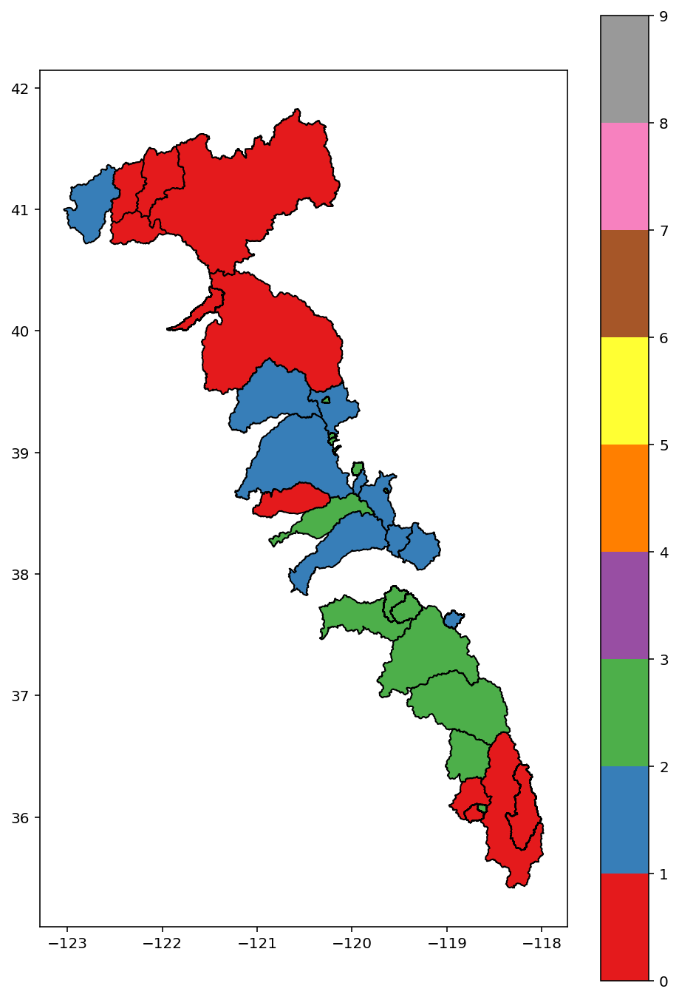

In [98]:
fig,ax = plt.subplots(1,figsize = (8,12))
gages[['STAID','geometry']].merge(clusterdf[['STAID','cluster']],on='STAID').plot(column='cluster',edgecolor = 'k',
                                                                                 legend=True,cmap = 'Set1',ax=ax,
                                                                                  vmin = 0,vmax = 9)

cluster 0


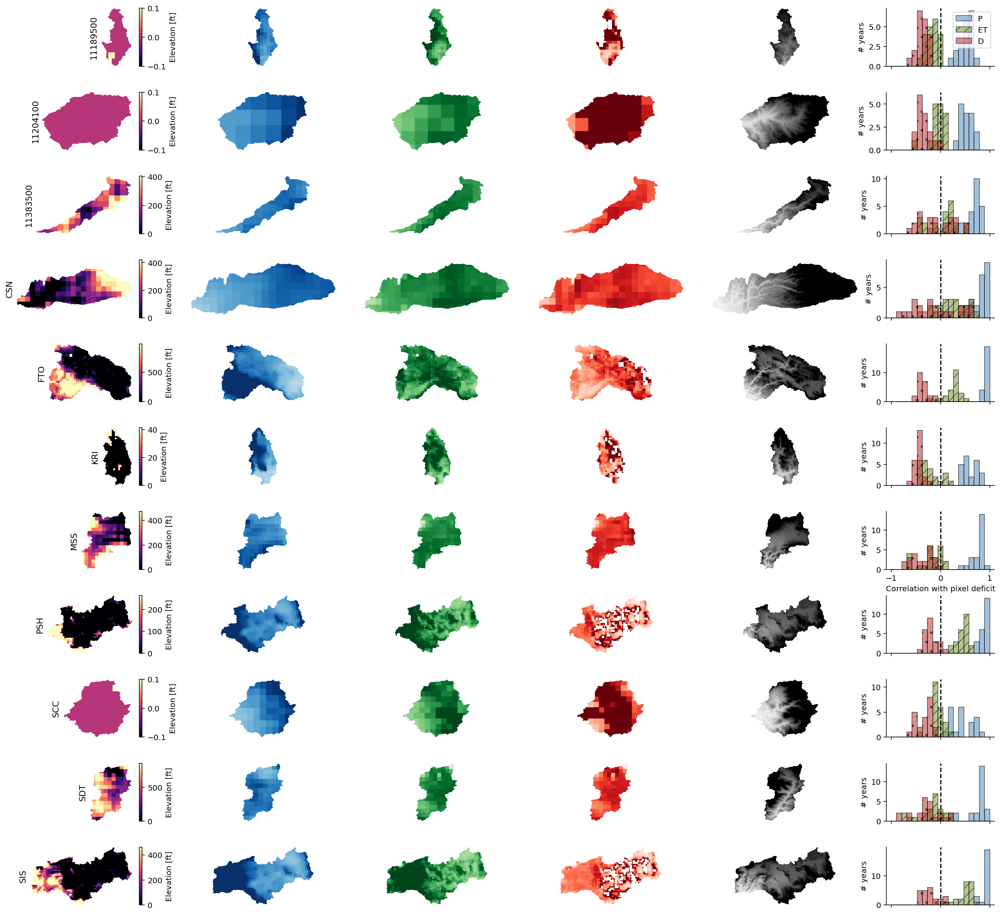


cluster 1


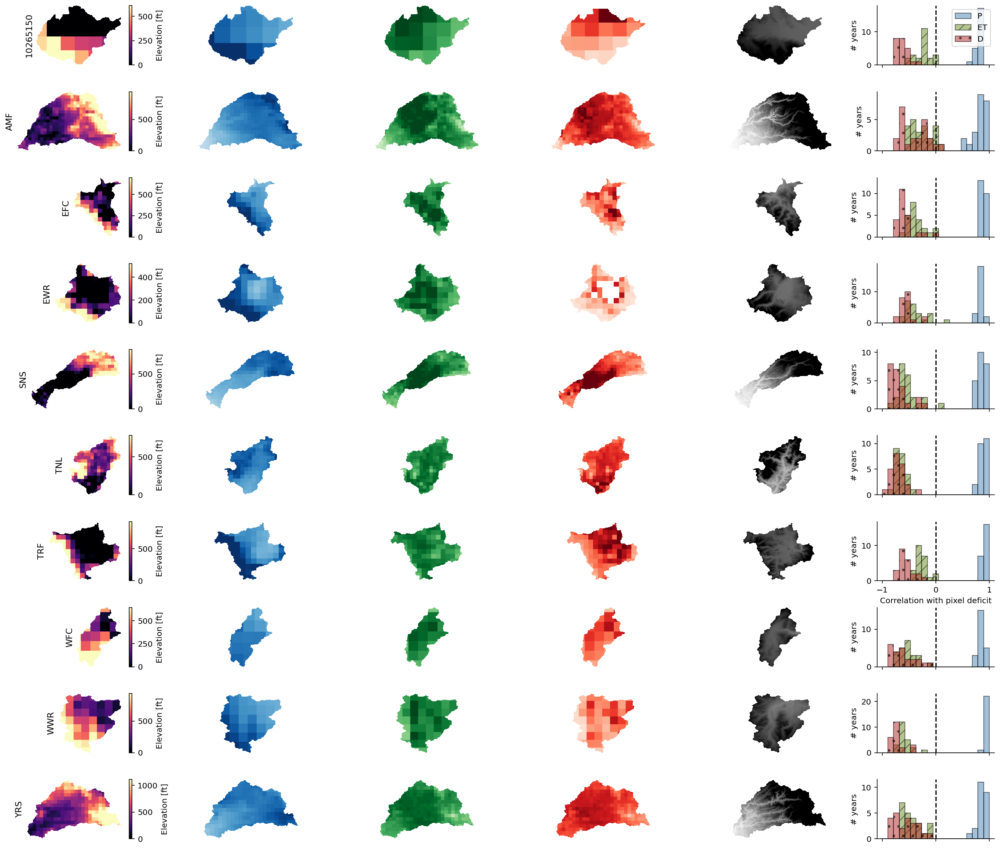


cluster 2


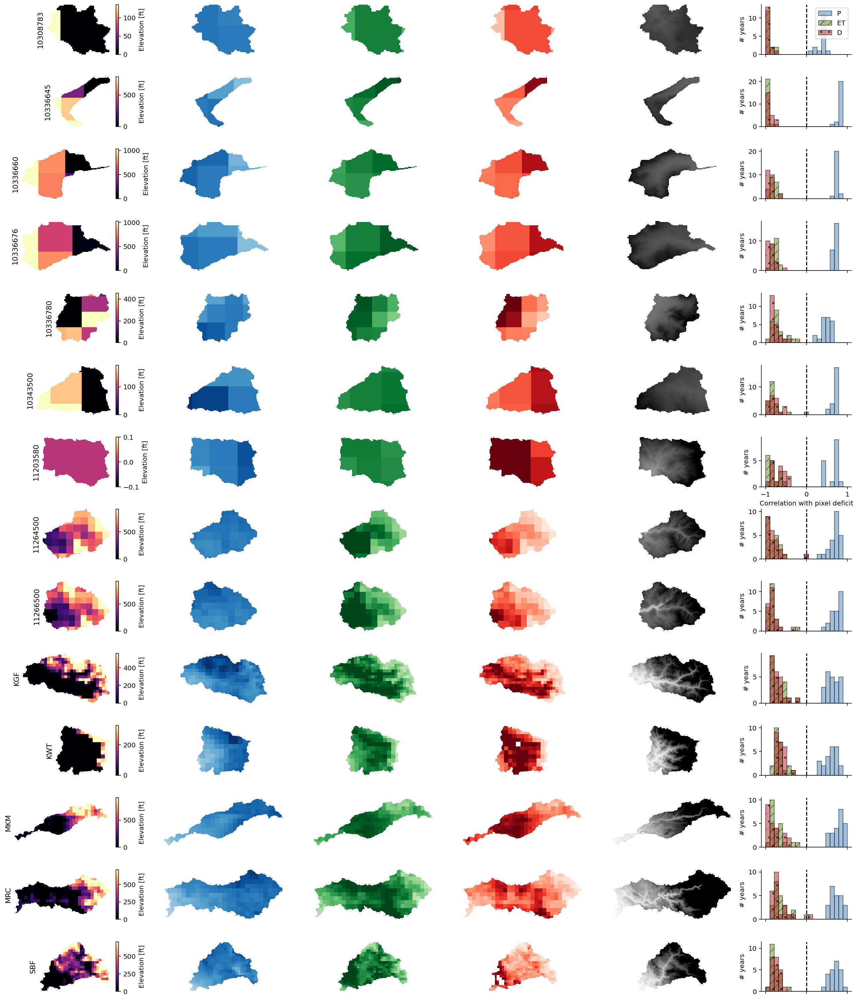

In [99]:

for clust in range(len(clusterdf.cluster.unique())):
    print('cluster',clust)
    plotgages = clusterdf[clusterdf.cluster==clust].STAID.values

    for year in [2021]:

      fig = plt.figure(figsize = (18,1.5*len(plotgages)), tight_layout=True)
      gs = GridSpec(len(plotgages),6, width_ratios = [12,12,12,12,12,9])
      axs = [fig.add_subplot(gs[i,0]) for i in range(len(plotgages))]
      axs1 = [fig.add_subplot(gs[i,1]) for i in range(len(plotgages))]
      axs2 = [fig.add_subplot(gs[i,2]) for i in range(len(plotgages))]
      axs3 = [fig.add_subplot(gs[i,3]) for i in range(len(plotgages))]
      axs4 = [fig.add_subplot(gs[i,4]) for i in range(len(plotgages))]
      axs5 = [fig.add_subplot(gs[i,5]) for i in range(len(plotgages))]
      axs = [axs,axs1,axs2,axs3,axs4]
      cmap_use = 'magma'

      cmaps = [cmap_use,'Blues','Greens','Reds','Greys']
      barlabels = ['WY Q [mm]','WY P [mm]','WY ET [mm]',
                   'Oct. 1 Deficit [mm]','Elevation [ft]']

      for j, key in enumerate(plotgages):

        d = import_Dpix(key)
        ddd = d[d.index=='9-30-2021'].DpixArray.values[0]
        mask = (ddd>np.nanmedian(ddd*4))&(ddd>200)
        maxD = min([1000,d.Dpixel.max()*1.5])
        d = d[d.index=='9-30-'+str(year)].DpixArray.values[0]
        d = np.where(mask,np.nan,d)
        ars = import_arrays_wy(key)
        ars['year'] = list(range(2001,2024))
        ars.set_index('year',inplace=True)
        q1 = import_Qpix(key)
        q1['year'] = q1.index.year
        qq = q1[q1.year==year].QpixArray.sum()

        pp = ars[ars.index==(year)].Parray.values[0]
        etet = ars[ars.index==(year)].ETarray.values[0]
        elev = elevations[elevations.STAID==key].elevation.values[0]

        mults = [1,1.4,1.25,1.25,1.25]

        for i,ar in enumerate([qq,pp,etet,d,elev]):
          ax = axs[i][j]
          if i==3:
            im = ax.imshow(ar,
                          vmin = 0, vmax = maxD, cmap = cmaps[i])
          elif i==0:
            im = ax.imshow(ar,
                          vmin = 0, vmax = np.nanpercentile(ar,90), cmap = cmaps[i])
          else:
            im = ax.imshow(ar,
                          vmin = 0, vmax = np.nanmedian(ar)*mults[i],
                           cmap = cmaps[i])
          ax.spines[['top','right','bottom','left']].set_visible(False)
          ax.set_xticks([])
          ax.set_yticks([])
          # if j==0:
          #   ax.set_title('Oct. '+str(date)+'\n\n')
          if i==0:
            ax.set_ylabel(key,fontsize = 11)
            cbar = plt.colorbar(im, ax = ax)
          cbar.set_label(barlabels[i])

        pdata = correlations_Q[correlations_Q.basin==key].set_index('year').drop(columns=['basin',]).sort_index()
        if len(pdata)==0:
            try:
                pdata = correlations_Q[correlations_Q.basin==int(key)].set_index('year').drop(columns=['basin',]).sort_index()
            except:
                pdata = correlations[correlations_Q.basin==(key)].set_index('year').drop(columns=['basin',]).sort_index()

        ax = axs5[j]
        ax.hist(pdata.Q_P,facecolor = 'steelblue',edgecolor = 'k',alpha=.5,bins = np.linspace(-1,1,20),label='P')
        ax.hist(pdata.Q_ET,facecolor = 'olivedrab',edgecolor = 'k',alpha=.5,bins = np.linspace(-1,1,20),label='ET',
                hatch='//')
        ax.hist(pdata.Q_D,facecolor = 'firebrick',edgecolor = 'k',alpha=.5,bins = np.linspace(-1,1,20),label='D',
                hatch='.')
        if j==0:
          ax.legend()
        if j==6:
          ax.set_xlabel('Correlation with pixel deficit')
        else:
          ax.set_xticklabels([])
        ax.axvline(0,c='k',ls='--')
        ax.set_ylabel('# years')
        ax.spines[['top','right']].set_visible(False)

      fig.tight_layout()

      plt.subplots_adjust(hspace=.45,)
      plt.savefig('deficit_pixel_maps_'+str(year)+'.png',format='png',dpi=300,bbox_inches='tight')
      plt.show()
    print('')

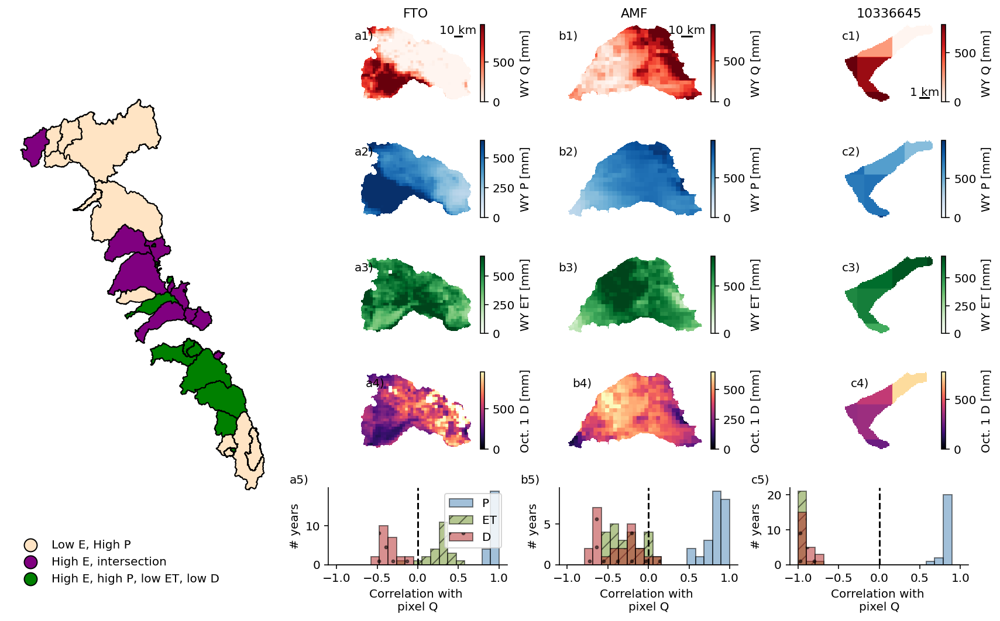

In [100]:

plotgages = ['FTO','AMF',cabasins.STAID.values[8],]

for year in [2021]:

  fig = plt.figure(figsize = (12,2.5*len(plotgages)), tight_layout=True)
  gs = GridSpec(5, len(plotgages)+1,width_ratios=[1.5,1,1,1])
  axmap = fig.add_subplot(gs[:,0])
  axs = [fig.add_subplot(gs[0,i+1]) for i in range(len(plotgages))]
  axs1 = [fig.add_subplot(gs[1,i+1]) for i in range(len(plotgages))]
  axs2 = [fig.add_subplot(gs[2,i+1]) for i in range(len(plotgages))]
  axs3 = [fig.add_subplot(gs[3,i+1]) for i in range(len(plotgages))]
  axs4 = [fig.add_subplot(gs[4,i+1]) for i in range(len(plotgages))]
  axs = [axs,axs1,axs2,axs3]
  cmap_use = 'magma'

  cmaps = ['Reds','Blues','Greens',cmap_use]
  barlabels = ['WY Q [mm]','WY P [mm]','WY ET [mm]','Oct. 1 D [mm]']

    
  ypos = [.15,.15,.95,.95
         ]
  xpos = [.85]*4

  scalesize = [100,100,10,100]
  for j, key in enumerate(plotgages[:]):

    d = import_Dpix(key)
    ddd = d[d.index=='9-30-2021'].DpixArray.values[0]
    mask = (ddd>np.nanmedian(ddd*4))&(ddd>200)
    maxD = min([1000,d.Dpixel.max()*1.5])
    d = d[d.index=='9-30-'+str(year)].DpixArray.values[0]
    d = np.where(mask,np.nan,d)
    ars = import_arrays_wy(key)
    ars['year'] = list(range(2001,2024))
    ars.set_index('year',inplace=True)
    
    q1 = import_Qpix(key)
    q1['year'] = q1.index.year
    qq = q1[q1.year==year].QpixArray.sum()

    

    pp = ars[ars.index==(year)].Parray.values[0]
    etet = ars[ars.index==(year)].ETarray.values[0]

    mults = [1,1.4,1.25,1]

    for i,ar in enumerate([qq,pp,etet,d,]):
      ax = axs[i][j]
      if i==3:
        im = ax.imshow(ar,
                      vmin = 0, vmax = maxD, cmap = cmaps[i])
        
      elif i!=0:
        im = ax.imshow(ar,
                      vmin = 0, vmax = np.nanmedian(ar)*mults[i],
                       cmap = cmaps[i])
      elif i==0:
        im = ax.imshow(ar,
                      vmin = 0, vmax = np.nanpercentile(ar,90),
                       cmap = cmaps[i])
        ax.plot([int(len(ar[0])*xpos[j]),int(len(ar[0])*xpos[j])+scalesize[j]],[int(len(ar)*ypos[j])]*2,c='k')
        ax.text(int(len(ar[0])*xpos[j])+scalesize[j]/2,int(len(ar)*(ypos[j])),
                str(int(scalesize[j]/10))+' km',ha='center',va = 'bottom')
      ax.spines[['top','right','bottom','left']].set_visible(False)
      ax.set_xticks([])
      ax.set_yticks([])

      if i==0:
        ax.set_title(key,fontsize = 11)

      cbar = plt.colorbar(im, ax = ax)
      cbar.set_label(barlabels[i])

    pdata = correlations_Q[correlations_Q.basin==key].set_index('year').drop(columns=['basin',]).sort_index()
    if len(pdata)==0:
        try:
            pdata = correlations[correlations_Q.basin==int(key)].set_index('year').drop(columns=['basin',]).sort_index()
        except:
            pdata = correlations[correlations_Q.basin==(key)].set_index('year').drop(columns=['basin',]).sort_index()

    ax = axs4[j]
    ax.hist(pdata.Q_P,facecolor = 'steelblue',edgecolor = 'k',alpha=.5,bins = np.linspace(-1,1,20),label='P')
    ax.hist(pdata.Q_ET,facecolor = 'olivedrab',edgecolor = 'k',alpha=.5,bins = np.linspace(-1,1,20),label='ET',
            hatch='//')
    ax.hist(pdata.Q_D,facecolor = 'firebrick',edgecolor = 'k',alpha=.5,bins = np.linspace(-1,1,20),label='D',
            hatch='.')
    if j==0:
      ax.legend()
    if j<len(plotgages):#-1:
      ax.set_xlabel('Correlation with \npixel Q')
    else:
      ax.set_xticklabels([])
    ax.axvline(0,c='k',ls='--')
    ax.set_ylabel('# years')
    ax.spines[['top','right']].set_visible(False)


    
  ax = axmap
  clusterdf['cluster1'] = np.where(clusterdf.cluster==0,2,clusterdf.cluster)
  clusterdf['cluster1'] = np.where(clusterdf.cluster==1,1,clusterdf.cluster1)
  clusterdf['cluster1'] = np.where(clusterdf.cluster==2,0,clusterdf.cluster1)
  withclusters = gages[['STAID','geometry']].merge(clusterdf[['STAID','cluster1','cluster']],on='STAID')
  clustercolors = {2:'bisque',
           1:'purple',
           0:'green'}
  clusterlabels1 = {2:'Low E, High P',
                   1:'High E, intersection',
                   0:'High E, high P, low ET, low D'}
  for cluster in [2,1,0]:
    withclusters[withclusters.cluster1==cluster].plot(edgecolor = 'k',
                                                     facecolor = clustercolors[cluster],ax=ax,
                                                    )
    ax.scatter([-120.5],[39.5],c=clustercolors[cluster],
              edgecolor = 'k',s=120,zorder=-100,label=clusterlabels1[cluster])
  ax.legend(loc = 'lower left',bbox_to_anchor = (0,-.2),
           frameon=False)
  ax.axis('off')
    
  fig.tight_layout()



  labels = ['a)','b)','c)','d)','e)','f)','g)','h)','i)']
  for j,ax in enumerate(axs[0]):
      ax.annotate(
          labels[j][:-1]+'1)',
          xy=(-.1, 1), xycoords='axes fraction',
          xytext=(+0.5, -0.5), textcoords='offset fontsize',
          verticalalignment='top', c='k')
      axs[1][j].annotate(
          labels[j][:-1]+'2)',
          xy=(-.10, 1), xycoords='axes fraction',
          xytext=(+0.5, -0.5), textcoords='offset fontsize',
          verticalalignment='top', c='k')
      axs[2][j].annotate(
          labels[j][:-1]+'3)',
          xy=(-.10, 1), xycoords='axes fraction',
          xytext=(+0.5, -0.5), textcoords='offset fontsize',
          verticalalignment='top', c='k')
      axs[3][j].annotate(
          labels[j][:-1]+'4)',
          xy=(.0, 1), xycoords='axes fraction',
          xytext=(+0.5, -0.5), textcoords='offset fontsize',
          verticalalignment='top', c='k')
      axs4[j].annotate(
          labels[j][:-1]+'5)',
          xy=(-.25, 1.25), xycoords='axes fraction',
          xytext=(+0.5, -0.5), textcoords='offset fontsize',
          verticalalignment='top', c='k')



  plt.subplots_adjust(hspace=.5,)
  plt.savefig('Q_pixel_maps_'+str(year)+'.png',format='png',dpi=300,bbox_inches='tight')
  plt.show()

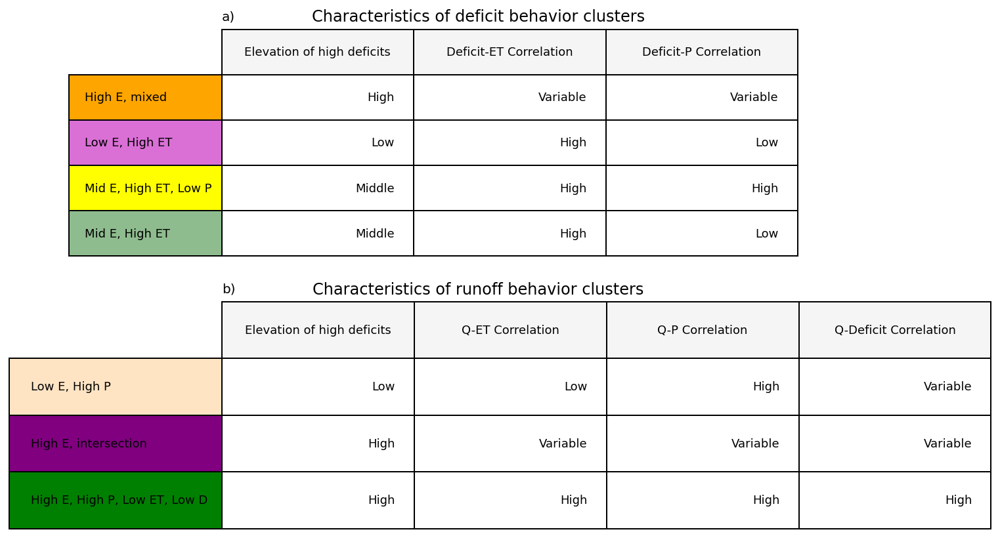

In [101]:
fig,axs = plt.subplots(2,figsize = (7,7))

ax = axs[0]
clustersummary = {'Cluster name':['High E, mixed',
                                 'Low E, High ET',
                                 'Mid E, High ET, Low P',
                                 'Mid E, High ET'],
                 'Elevation of high deficits':['High','Low','Middle',
                             'Middle',],
                 'Deficit-ET Correlation':['Variable',
                                    'High',
                                    'High','High'],
                 'Deficit-P Correlation':['Variable','Low','High', 'Low']}
clustersummary = pd.DataFrame.from_dict(clustersummary)
clustersummary.style.set_properties(subset=['Cluster name'], **{'background-color': 'lightblue'})
clustersummary.set_index('Cluster name',inplace=True)

tab = pd.plotting.table(ax, clustersummary, 
                  loc='center',
                  rowColours = ['orange','orchid','yellow','darkseagreen'],
                        colColours=['whitesmoke']*3,
                        bbox=[0, 0, 1.123, 1]
                 )
ax.axis('off')
for key, cell in tab.get_celld().items():
    cell.set_height(0.2)
    cell.set_width(0.5)
    cell.set_fontsize(30)
ax.set_title('Characteristics of deficit behavior clusters')
ax.text(.0,1.04,'a)')


ax = axs[1]
clustersummary = {'Cluster name':['Low E, High P',
                                 'High E, intersection',
                                 'High E, High P, Low ET, Low D'],
                 'Elevation of high deficits':['Low','High','High',],
                 'Q-ET Correlation':['Low','Variable','High'],
                 'Q-P Correlation':['High','Variable','High'],
                 'Q-Deficit Correlation':['Variable','Variable','High']}
clustersummary = pd.DataFrame.from_dict(clustersummary)
clustersummary.style.set_properties(subset=['Cluster name'], **{'background-color': 'lightblue'})
clustersummary.set_index('Cluster name',inplace=True)

tab = pd.plotting.table(ax, clustersummary, 
                  loc='center',
                  rowColours = ['bisque','purple','green'],
                        colColours=['whitesmoke']*4,
                        bbox=[0, 0, 1.5, 1]
                 )
ax.axis('off')
for key, cell in tab.get_celld().items():
    cell.set_height(0.2)
    cell.set_width(0.5)
    cell.set_fontsize(20)
ax.set_title('Characteristics of runoff behavior clusters')
ax.text(.0,1.04,'b)')

plt.savefig('clustertables.png',format='png',dpi=300,bbox_inches='tight')

key
using FNF
key
using FNF
key
using FNF
key
using FNF
key
using FNF
key
using FNF
key
using FNF
key
using FNF
key
using FNF
key
using FNF
key
using FNF
key
using FNF
key
using FNF
key
using FNF
key
using FNF
key
using FNF
key
using FNF
key
using FNF
key
using FNF
key
using FNF
key
using FNF
key
using FNF
key
using FNF
no FNF. Using NWIS


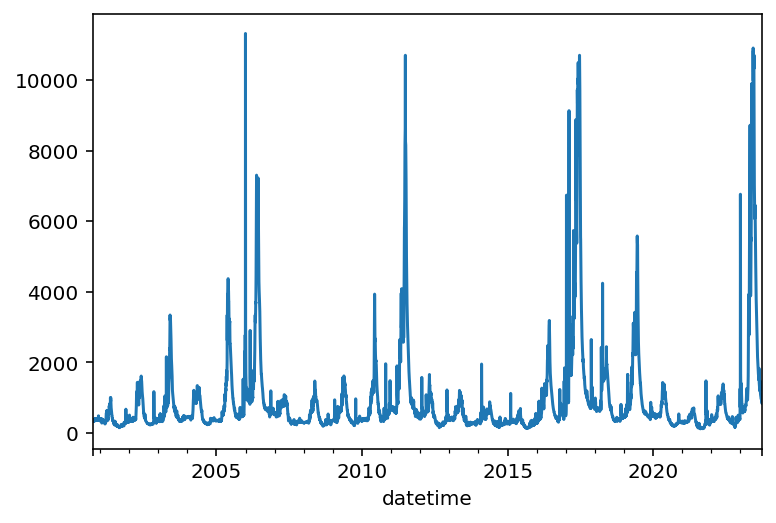

key
using FNF
no FNF. Using NWIS


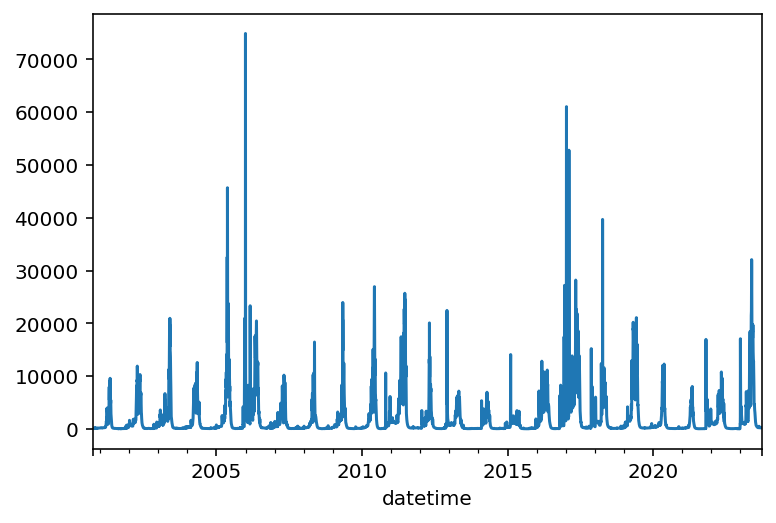

key
using FNF
no FNF. Using NWIS


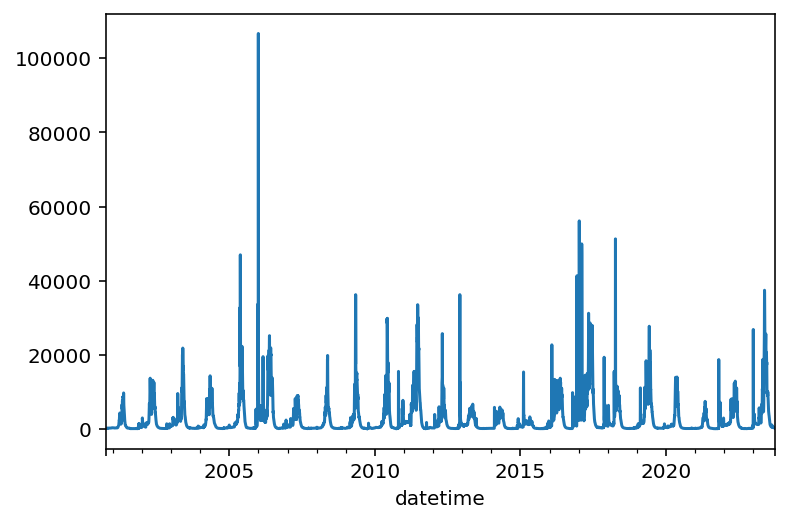

key
using FNF
no FNF. Using NWIS


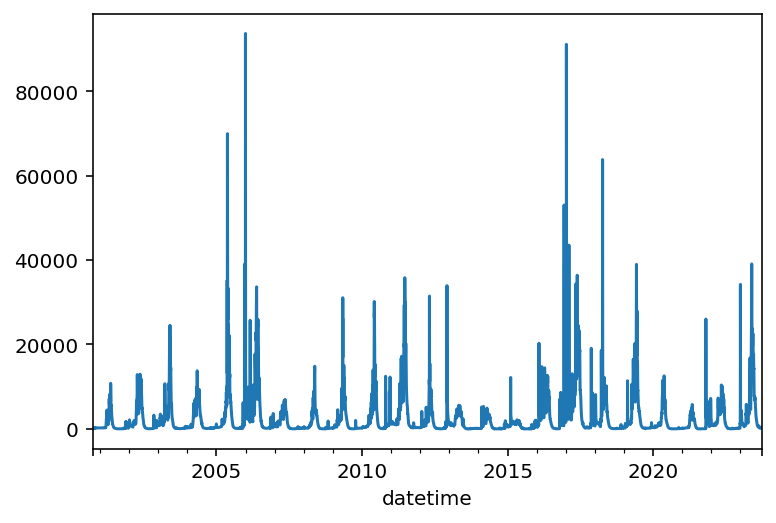

key
using FNF
no FNF. Using NWIS


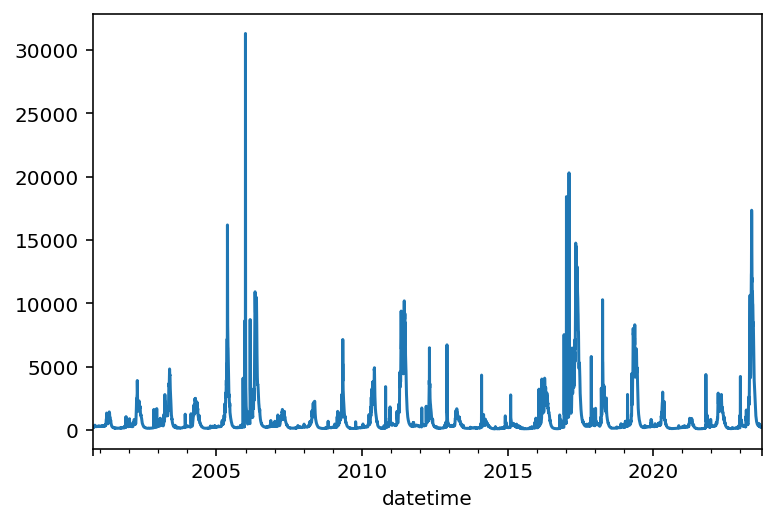

key
using FNF
no FNF. Using NWIS


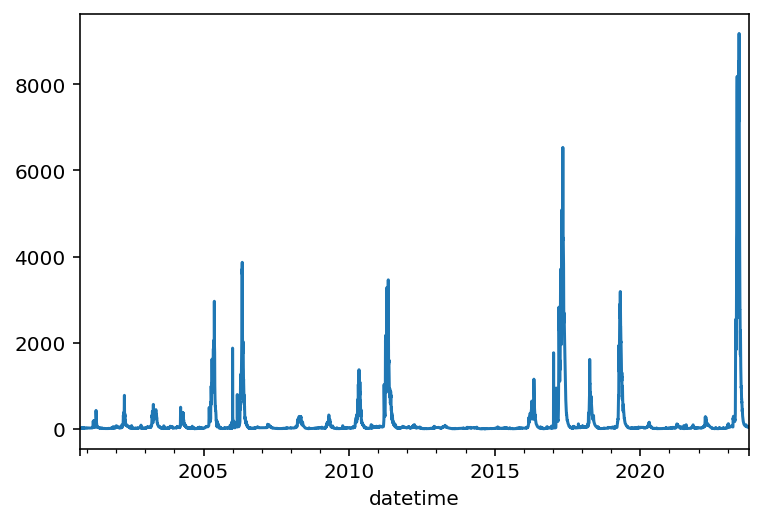

key
using FNF
no FNF. Using NWIS


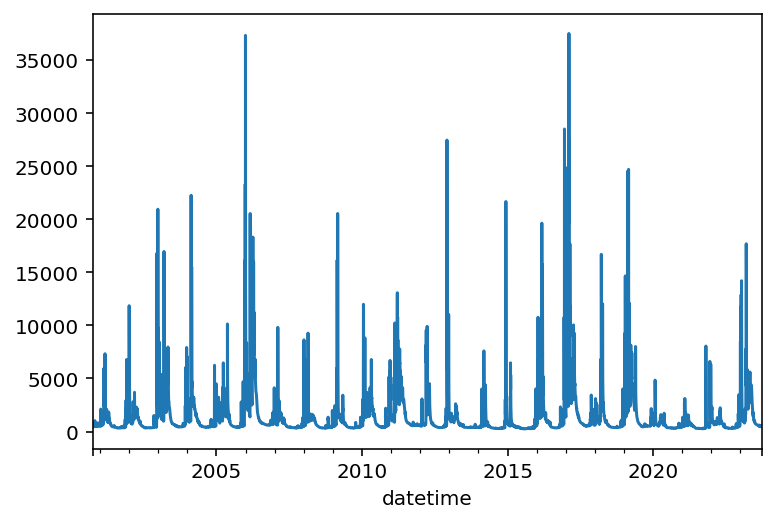

key
using FNF
no FNF. Using NWIS


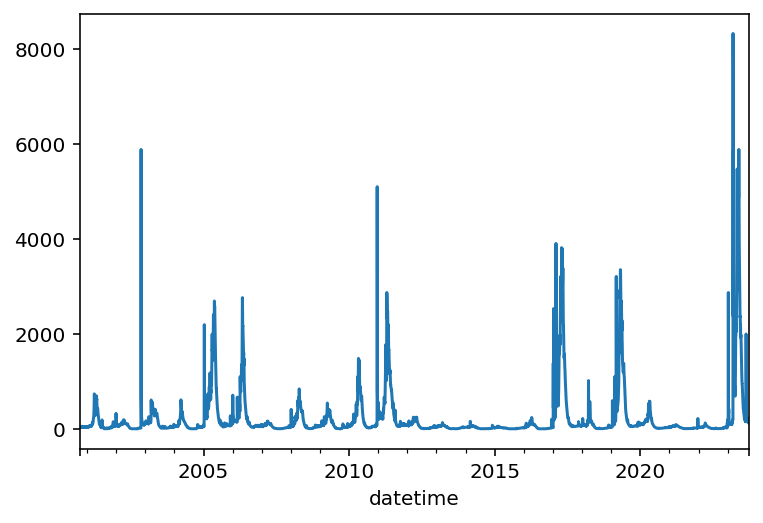

key
using FNF
no FNF. Using NWIS


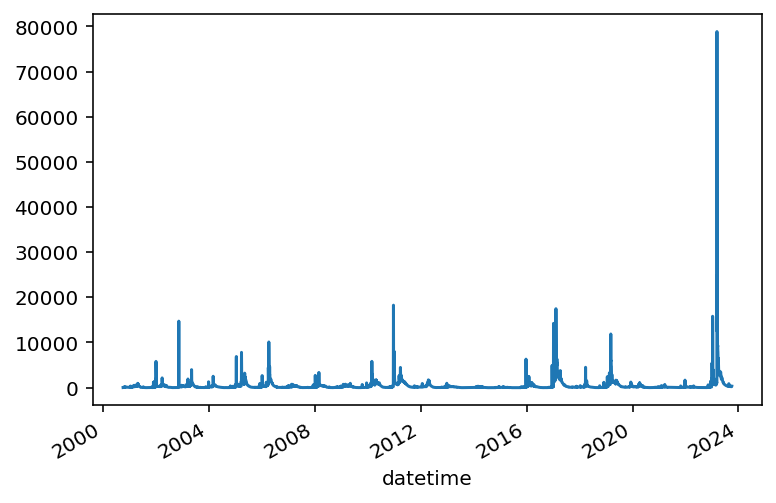

key
using FNF
no FNF. Using NWIS


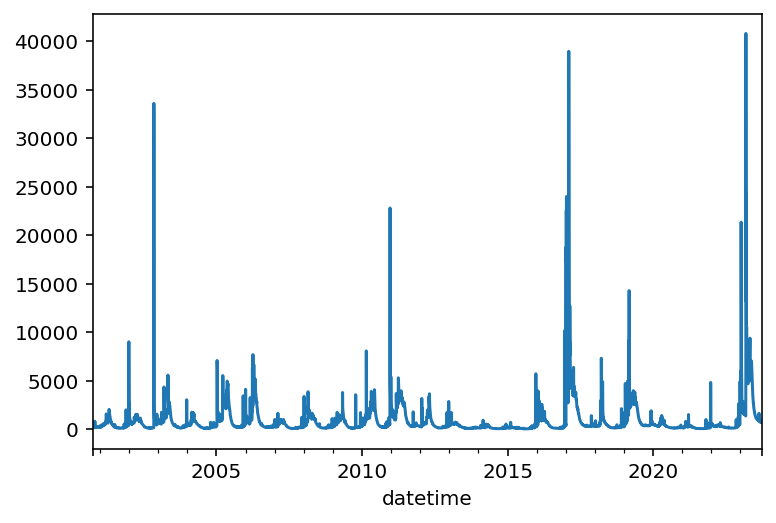

key
using FNF
no FNF. Using NWIS


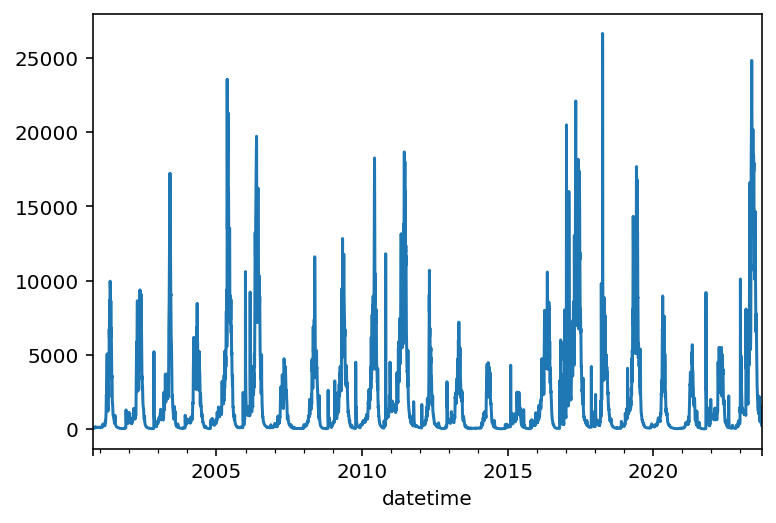

key
using FNF
no FNF. Using NWIS


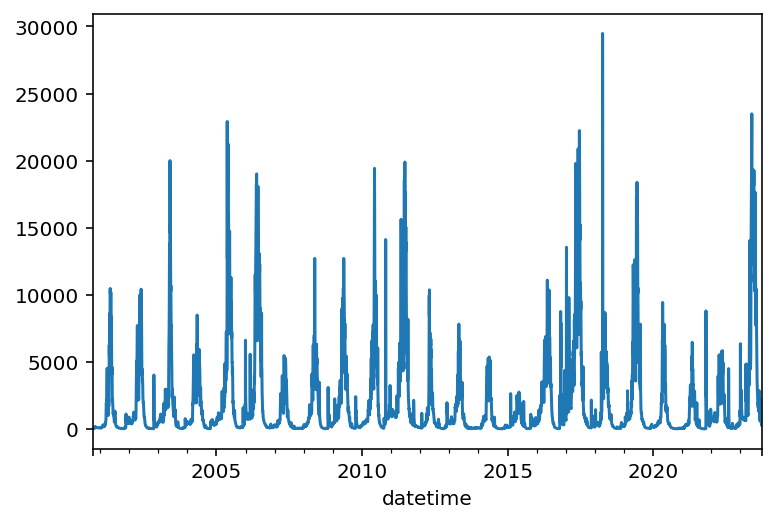

key
using FNF
no FNF. Using NWIS


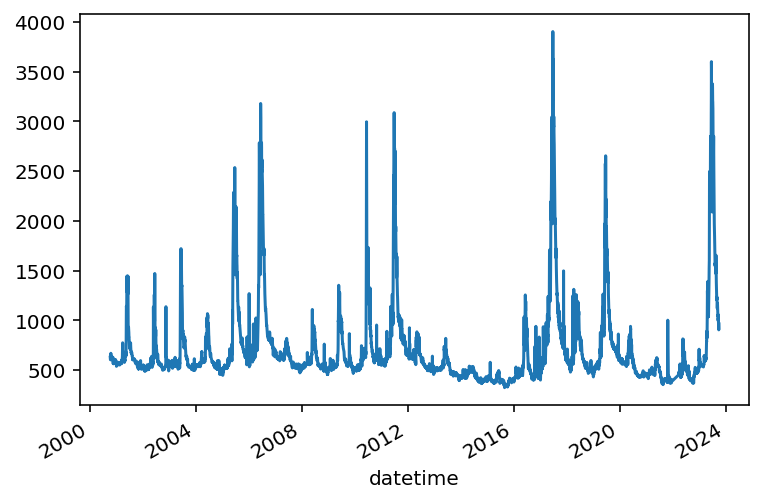

In [102]:
# bring in the Q data!!
Qdata = {}
Qyrs = {}
for key in list(gages.STAID.values)[:]:
    print('key')
    try:
        print('using FNF')
        qdata = pd.read_csv('../Data/FNF/FNF_processed.csv')
        qdata['DATE TIME'] = pd.to_datetime(qdata['DATE TIME'])
        qdata = qdata.set_index('DATE TIME')[[key]].rename(columns={key:'00060_Mean'})
        qdata['wy'] = np.where(qdata.index.month>=10,qdata.index.year+1,qdata.index.year)
        Qyr = qdata.groupby('wy')[['00060_Mean']].sum()
        Qyrs[key] = Qyr
        Qdata[key] = qdata['00060_Mean']
    except:
        print('no FNF. Using NWIS')
        qdata = nwis.get_record(sites=str(key), service='dv', start='2000-10-01', end='2023-10-01',parameterCd='00060').reset_index()
        qdata.set_index('datetime',inplace=True)
        (qdata['00060_Mean']/gages[gages.STAID==key].Area_sqkm.values[0]*12**3*2.54**3/100**3*60*60*24).plot()
        plt.show()
        qdata['wy'] = np.where(qdata.index.month>=10,qdata.index.year+1,qdata.index.year)
        Qyr = qdata.groupby('wy')[['00060_Mean']].sum()*12**3*2.54**3/100**3*60*60*24/gages[gages.STAID==key].Area_sqkm.values[0]/1000000*1000
#         Qsprings[key] = qdata.groupby('wy')[['00060_Mean']].sum()*12**3*2.54**3/100**3*60*60*24/gages[gages.STAID==key].Area_sqkm.values[0]/1000000*1000
        Qyrs[key] = Qyr
        Qdata[key] = qdata['00060_Mean']*12**3*2.54**3/100**3*60*60*24/gages[gages.STAID==key].Area_sqkm.values[0]/1000000*1000




In [103]:
markers = ['o','s','^','*','>','p','X','D','P']*2

fig = plt.figure(figsize = (15,len(gages)*2), tight_layout=True)
gs = GridSpec(len(gages),5,width_ratios = [1.3,.8,.8,.8,.1])
axsmap = [fig.add_subplot(gs[i,3]) for i in range(len(gages))]
axsscatter = [fig.add_subplot(gs[i,1]) for i in range(len(gages))]
axstt = [fig.add_subplot(gs[i,2]) for i in range(len(gages))]
cax = fig.add_subplot(gs[:,-1])
axss = [fig.add_subplot(gs[i,0]) for i in range(len(gages))]

ys = [50,50,50,700,700,50,50,50,50]
xs = [25,25,700,25,550,25,25,25,25]
for i in range(len(gages)):
  qp = qps[i]
  ax = axsmap[i]
  im = ax.imshow(qp,cmap = 'Blues',vmin = 0, vmax = 1500)
  if i==0:
    cbar = plt.colorbar(im,cax=cax)
    cbar.set_label('WY mean pixel Q [mm]')


  ax.axis('off')

  qb = qbs[i]
  qbb = data1[gages.STAID.values[i]]

#   ax = axstt[i]
#   # put the correlations here
#   Qcorr = correlations_Q[correlations_Q.basin==gages.STAID.values[i]]
#   bins = np.linspace(-1,1,20)
#   ax.hist(Qcorr.Q_P,facecolor = 'steelblue',alpha=.5,edgecolor = 'k',bins=bins,label='P')
#   ax.hist(Qcorr.Q_ET,facecolor = 'olivedrab',alpha=.5,edgecolor = 'k',bins=bins,hatch='//',label='ET')
#   ax.hist(Qcorr.Q_D,facecolor = 'goldenrod',alpha=.5,edgecolor = 'k',bins = bins,hatch='..',label='D')
#   ax.set_ylim(0,15)
#   ax.set_ylabel('# years')
#   ax.set_xlabel('Correlation with pixel Q')
#   if i==0:
#     ax.legend()
#   ax.axvline(0,c='k',ls='--')
#   ax.spines[['top','right']].set_visible(False)

  ax = axss[i]
  ax.set_title(gages.STAID.values[i])#set_shortname(gages[gages.STAID==gages.STAID.values[i]].STANAME.values[0]))
  qbb['Q'] = -(qbb.D - qbb.P_adj + qbb.ET)
  qbb['Q'] = np.where(qbb.Q<0,0,qbb.Q)
  qbbb = qbb.groupby('wy').sum()
  qbbb['Qdiff'] = (qbbb.Q - qbbb.Qpixel)#/qbbb.Qpixel*100
  qbbb.Qdiff.plot(ax=ax,)# marker = markers[i])
  ax.set_ylabel('Difference between \nWY Q basin and pixel [mm]')
  ax.set_xlabel('')
  ax.spines[['top','right']].set_visible(False)
  ax.axhline(0,c='k',ls='--')
  # ax.set_ylim(-150,150)
  ax.set_xlim(2000,2024)
  ax.axhspan(-10,10,facecolor='k',alpha=.2,zorder = -1)
  ax.axhspan(-25,25,facecolor='k',alpha=.1,zorder = -1)


  ax = axsscatter[i]
  ax.scatter(qbbb.Q,qbbb.Qpixel,alpha=.5)#marker = markers[i],alpha=.5)
  ax.set_xlabel('WY $Q_{basin}$ [mm]')
  ax.set_ylabel('WY $Q_{pixel}$ [mm]')
  ax.spines[['top','right']].set_visible(False)
  # ax.set_ylabel('WY Q [mm]')
  ax.plot([0,max(qbbb.Q)*1.25],
          [0,max(qbbb.Q)*1.25],c='k',ls='--')

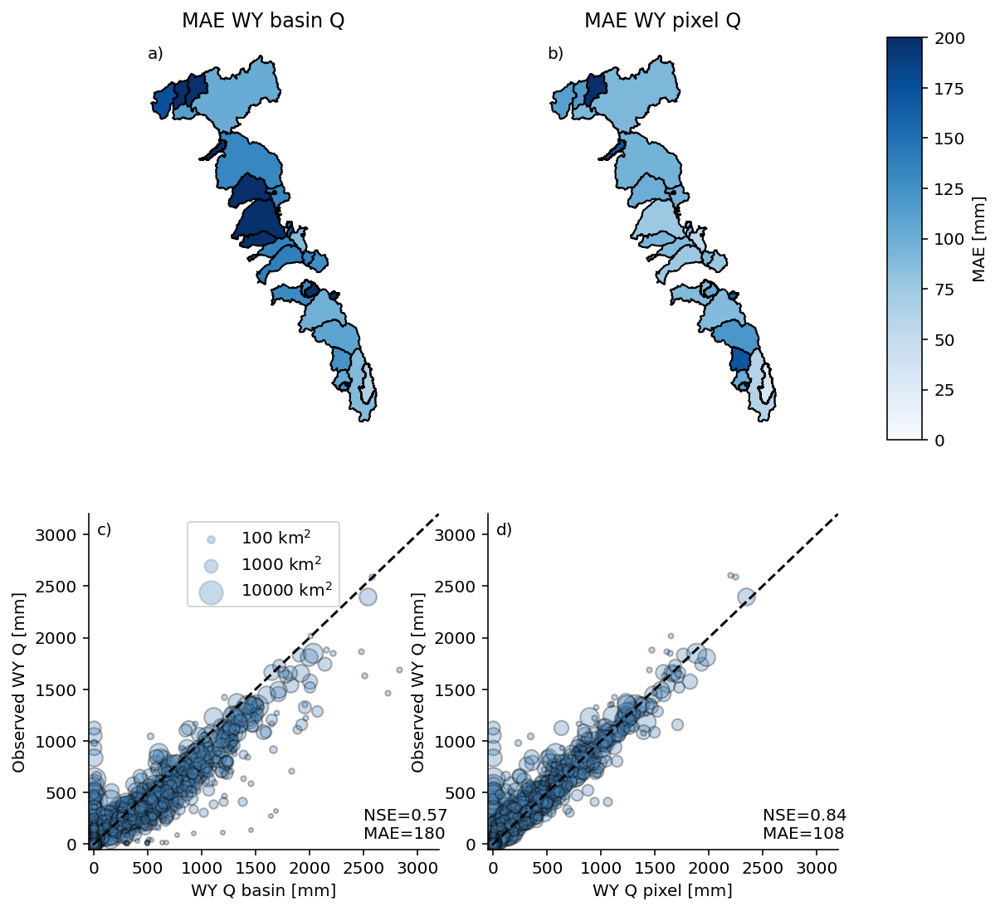

In [104]:
fig,axs = plt.subplots(2,3,figsize = (9,9), gridspec_kw={'height_ratios':[1.2,1],
                                                        'width_ratios':[1,1,.1]})
from sklearn.metrics import r2_score

Qfit = {'ID':[],
        'R2_pixel':[],
        'R2_basin':[],
        'MAE_pixel':[],
        'MAE_basin':[]}





qv = []
qb = []
qp = []
for i,key in enumerate(gages.STAID.values):
  qbbb = data1[key]
  qbbb = qbbb.groupby('wy').sum()
  qbbb = qbbb.merge(Qyrs[key],left_index=True,
                    right_index=True)
  ax = axs[1,0]
  if i<9:
    mark = 'o'
  else:
    mark = '<'
  ax.scatter(qbbb.Q,qbbb['00060_Mean'],#c='steelblue',#label=' '.join(gages.STANAME.values[i].replace('SF ','').split()[:2]),#
#              label = key,#set_shortname(gages.STANAME.values[i]),
#              marker = mark, 
             c = 'steelblue',
             s = gages[gages.STAID==key].Area_sqkm.values[0]**.5*2,
#              c = [gages[gages.STAID==key].LATITUDE.values[0]]*len(qbbb),
#              vmin = gages.LATITUDE.min(),vmax = gages.LATITUDE.max(),
#              cmap = 'plasma',
             alpha=.3, edgecolor = 'k')
  ax.set_xlabel('WY Q basin [mm]')

  qv = qv + list(qbbb['00060_Mean'].values.flatten())
  qb = qb + list(qbbb.Q.values.flatten())
  

  ax = axs[1,1]
  ax.scatter(qbbb.Qpixel,qbbb['00060_Mean'],#c='skyblue',
             label = key,#set_shortname(gages.STANAME.values[i]),
#              marker = mark, 
             s = gages[gages.STAID==key].Area_sqkm.values[0]**.5*2,
             c = 'steelblue',
             alpha=.3, edgecolor = 'k')
  ax.set_xlabel('WY Q pixel [mm]')
  qp = qp + list(qbbb.Qpixel.values.flatten())
  
#   if key == 'KRI':
#     print('rats')
#     axs[1].legend(loc = 'upper left',bbox_to_anchor = (.7,.7),ncol=2)


  Qfit['ID'].append(key)#gages.STAID.values[i])
  Qfit['R2_basin'].append(r2_score(qbbb.Q,qbbb['00060_Mean']))
  Qfit['R2_pixel'].append(r2_score(qbbb.Qpixel,qbbb['00060_Mean']))
  Qfit['MAE_pixel'].append(np.mean(np.abs(qbbb.Qpixel-qbbb['00060_Mean'])))
  Qfit['MAE_basin'].append(np.mean(np.abs(qbbb.Q-qbbb['00060_Mean'])))
for ax in axs[1][:-1]:
  ax.plot([-100,3200],[-100,3200],c='k',ls='--')
  ax.set_xlim(-50,3200)
  ax.set_ylim(-50,3200)
  ax.spines[['top','right']].set_visible(False)
  ax.set_ylabel('Observed WY Q [mm]')

axs[1,2].axis('off')

ax= axs[1,0]
r2val = r2_score(qv,qb)
maeval = np.nanmean(np.abs(np.array(qv)-np.array(qb)))
ax.text(2500,50,'NSE='+str(round(r2val,2))+'\nMAE='+str(round(maeval)))
for s in [100,1000,10000]:
    ax.scatter([-1000],[1000],label = str(s)+' km$^2$',
         s = s**.5*2,
         c = 'steelblue',
         alpha=.3,)
ax.legend()

ax= axs[1,1]
r2val = r2_score(qv,qp)
maeval = np.nanmean(np.abs(np.array(qv)-np.array(qp)))
ax.text(2500,50,'NSE='+str(round(r2val,2))+'\nMAE='+str(round(maeval)))



Qfit = pd.DataFrame.from_dict(Qfit)

qfitmap = gages[['STAID','geometry']].merge(Qfit[['ID','MAE_pixel','MAE_basin']].rename(columns={'ID':'STAID'}),
                                 on='STAID')
# fig,axs = plt.subplots(1,3,figsize = (9,8),gridspec_kw={'width_ratios':[1,1,.1]})

cmap = 'Blues'

for i,col in enumerate(['MAE_basin','MAE_pixel']):
    ax = axs[0,i]
    qfitmap.plot(column=col,ax=ax,cmap = cmap,edgecolor = 'k',
                legend=True,legend_kwds={'cax':axs[0,2],'label':'MAE [mm]'},#'orientation':'horizontal'},
                vmin = 0, vmax = 200)
    ax.axis('off')
    ax.set_title(' WY '.join(col.split('_'))+ ' Q')
    
    
    

labels = ['a)','b)','','c)','d)','','e)','f)','g)',
          'h)','i)','j)','k)','l)','m)','n)','o)','p)','q)','r)'
          ,]*4
for j,ax in enumerate(axs.flatten()):
    ax.annotate(
        labels[j],
        xy=(0, 1), xycoords='axes fraction',
        xytext=(+0.5, -0.5), textcoords='offset fontsize',
         verticalalignment='top', )

plt.savefig('Qfit_withmap.png',dpi=300,format='png',bbox_inches='tight')

In [115]:
Qfit['meanQ'] = Qfit.ID.apply(lambda ID: Qyrs[ID].mean().values[0])
# Qfit




In [113]:

divfrac = 1
plotgages1 = plotgages
plotgages = gages.STAID.values

fig,axs = plt.subplots(len(plotgages),3,figsize = (14,2.2*len(list(plotgages))),
                       gridspec_kw={'width_ratios':[1.5,1,1]})

for i,key in enumerate(plotgages):
  ax = axs[i,0]
  ax.set_title(key)
  ax.set_ylabel('WY Q [mm]')
  site = key
  qdat = Qdata[site].resample('M').sum()
  data = data1[site]
  data['Q'] = data.P_adj - data.ET - data.D
  data['Q'] = np.where(data.Q<0,0,data.Q)
  data = data.merge(qdat.tz_localize(None),left_index=True,right_index=True)
  ax.plot(data[['00060_Mean','wy']].groupby('wy').sum(),label = 'Actual Q',c = 'k', ls=':')
  ax.plot(data[['Q','wy']].groupby('wy').sum(), label = 'Basin Q',c = 'steelblue')
  ax.plot(data[['Qpixel','wy']].groupby('wy').sum(), label = 'Pixel Q',c = 'skyblue')

  if i==0:
    ax.legend(loc = 'lower left')
  if i<len(plotgages)-1:
    ax.set_xticklabels([])

  def mae_score(d1,d2):
    diff = np.abs(d1.values-d2.values)
    return np.nanmean(diff)

  r2val = mae_score(data[['00060_Mean','wy']].groupby('wy').sum(),
                   data[['Q','wy']].groupby('wy').sum())
  r2val1 = mae_score(data[['00060_Mean','wy']].groupby('wy').sum(),
                   data[['Qpixel','wy']].groupby('wy').sum())


  ax = axs[i,1]
  start = '2007-5-01'
  end = '2009-10-01'
  ax.plot(data.loc[start:end][['Q',]],c='steelblue',label='basin Q')
  ax.plot(data.loc[start:end][['Qpixel',]],c='skyblue',label = 'pixel Q')
  ax.plot(data.loc[start:end][['00060_Mean']],
          c='k',ls=':', label = 'gage Q')
  axt = ax.twinx()

  axt.plot(data1[key].loc[start:end].D,#dd.shift(2).loc[start:end].q75,
           c='firebrick',label='basin D')
  datadata = data1[key].copy()
  datadata['Dpixel'] = q50dict[gages.STAID.values[i]]
  axt.plot(datadata.loc[start:end].Dpixel,#dd.shift(2).loc[start:end].q75,
           c='orange',label='pixel D')#ls=':')
  axt.set_ylabel('Deficit [mm]')
  axt.spines[['top']].set_visible(False)
  if i==0:
    axt.legend(loc = 'lower left')
  ax.set_ylabel('monthly Q [mm]')
  # ax.axhline(0,c='k',ls='--')
  if i<len(plotgages)-1:
    ax.set_xticklabels([])
  else:
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))

  ax = axs[i,2]
  qpixdata = import_Qpix(key)
  qpixdata['wy'] = np.where(qpixdata.index.month>=10,qpixdata.index.year+1,qpixdata.index.year)
  wynum = len(qpixdata.wy.unique())
  qpixdata = qpixdata[['QpixArray']].sum()/wynum
  arr = qpixdata.values[0]
  im = ax.imshow(arr,cmap = 'Blues')
  cbar = plt.colorbar(im)
  cbar.set_label('mean WY Q pixel [mm]')
  ax.axis('off')

for ax in axs.flatten():
  ax.spines[['top','right']].set_visible(False)
fig.tight_layout()

labels = ['a)','b)','c)','d)','e)','f)','g)',
          'h)','i)','j)','k)','l)','m)','n)','o)','p)','q)','r)'
          ,]*4
for j,ax in enumerate(axs):
    ax[0].annotate(
        labels[j][:-1]+'1)',
        xy=(0, 1), xycoords='axes fraction',
        xytext=(+0.5, -0.5), textcoords='offset fontsize',
         verticalalignment='top', )
    ax[1].annotate(
        labels[j][:-1]+'2)',
        xy=(0, 1), xycoords='axes fraction',
        xytext=(+0.5, -0.5), textcoords='offset fontsize',
         verticalalignment='top', )
    ax[2].annotate(
        labels[j][:-1]+'3)',
        xy=(0, 1), xycoords='axes fraction',
        xytext=(+0.5, -0.5), textcoords='offset fontsize',
         verticalalignment='top', )

plt.savefig('Q_results.png',format='png',dpi=300,bbox_inches='tight')

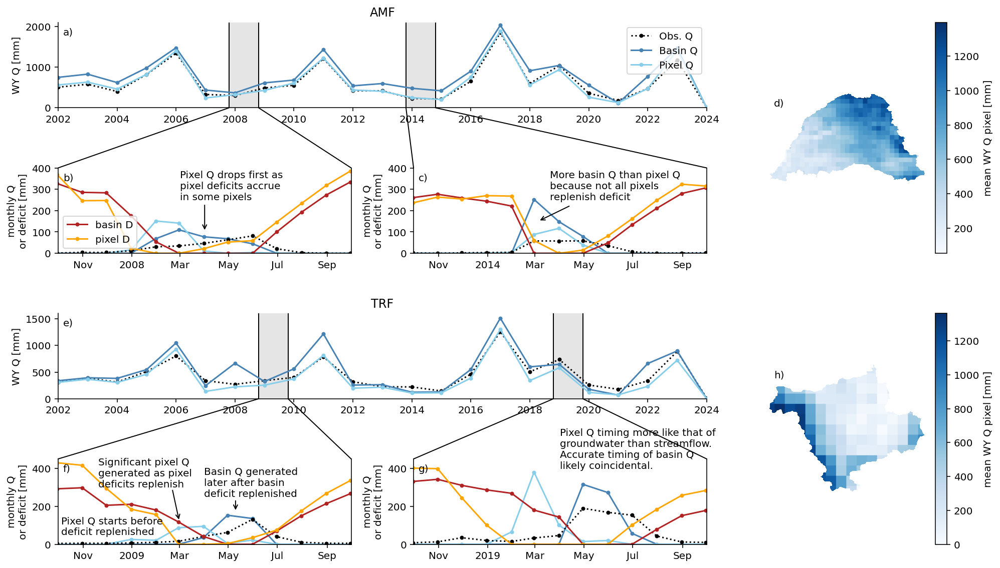

In [114]:
from matplotlib.patches import ConnectionPatch
# 
divfrac = 1
plotgages1 = plotgages
plotgages = ['AMF','TRF',]


fig = plt.figure(figsize = (14,4*len(plotgages)), tight_layout=True)
gs = GridSpec(len(plotgages)*2,3, width_ratios=[1.5,1.5,1])
axs = [fig.add_subplot(gs[i*2,:2]) for i in range(len(plotgages))]
axs1 = [fig.add_subplot(gs[i*2+1,0]) for i in range(len(plotgages))]
axs2 = [fig.add_subplot(gs[i*2+1,1]) for i in range(len(plotgages))]
axm = [fig.add_subplot(gs[(i*2):(i*2+2),2]) for i in range(len(plotgages))]

for i,key in enumerate(plotgages):
  ax = axs[i]
  ax.set_title(key)#set_shortname(gages[gages.STAID==gages.STAID.values[i]].STANAME.values[0]))
  ax.set_ylabel('WY Q [mm]')
  site = key#gages.STAID.values[i]
  qdat = Qdata[site].resample('M').sum()
  data = data1[site]
  data['Q'] = data.P_adj - data.ET - data.D
  data['Q'] = np.where(data.Q<0,0,data.Q)
  data = data.merge(qdat.tz_localize(None),left_index=True,right_index=True)
  ax.plot(data[['00060_Mean','wy']].groupby('wy').sum(),label = 'Obs. Q',c = 'k', ls=':',
         marker = '.')
  ax.plot(data[['Q','wy']].groupby('wy').sum(), label = 'Basin Q',c = 'steelblue',
         marker = '.')
  ax.plot(data[['Qpixel','wy']].groupby('wy').sum(), label = 'Pixel Q',c = 'skyblue',
         marker = '.')
  ax.spines[['top','right']].set_visible(False)
  ax.set_xlim(2002,2024)
  ax.set_xticks(list(range(2002,2025,2)))


  if i==0:
    ax.legend(loc = 'upper right')#loc = 'lower left')


  def mae_score(d1,d2):
    diff = np.abs(d1.values-d2.values)
    return np.nanmean(diff)

  r2val = mae_score(data[['00060_Mean','wy']].groupby('wy').sum(),
                   data[['Q','wy']].groupby('wy').sum())
  r2val1 = mae_score(data[['00060_Mean','wy']].groupby('wy').sum(),
                   data[['Qpixel','wy']].groupby('wy').sum())

  starts = [['2007-10-01','2013-10-01'],
           ['2008-10-01','2018-10-01']]
  ends = [['2008-10-01','2014-10-01'],
         ['2009-10-01','2019-10-01']]
  maxvals = [[400,400],[450,450]]
  maxmax = [2100,1600]
  for j,ax in enumerate([axs1[i],axs2[i]]):
      start = starts[i][j]
      end = ends[i][j]
      ax.plot(data.loc[start.replace('10','09'):end][['Q',]],c='steelblue',label=None,#'basin Q',
             marker = '.')
      ax.plot(data.loc[start.replace('10','09'):end][['Qpixel',]],c='skyblue',label = None,#'pixel Q',
             marker = '.')
      ax.plot(data.loc[start.replace('10','09'):end][['00060_Mean']],
              c='k',ls=':', label = None,#'Obs. Q',
             marker = '.')
      axt = ax#.twinx()
      ax.set_xlim(pd.to_datetime(start),
                  pd.to_datetime(end))

      axt.plot(data1[key].loc[start.replace('10','09'):end].D,#dd.shift(2).loc[start:end].q75,
               c='firebrick',label='basin D',marker = '.')
      datadata = data1[key].copy()
      datadata['Dpixel'] = q50dict[gages.STAID.values[i]]
      axt.plot(datadata.loc[start.replace('10','09'):end].Dpixel,marker = '.',#dd.shift(2).loc[start:end].q75,
               c='orange',label='pixel D')#ls=':')
      axt.set_ylabel('Deficit [mm]')
      axt.spines[['top',]].set_visible(False)
      if (i==0) &(j==0):
        axt.legend(loc = 'lower left')

      ax.set_ylabel('monthly Q\nor deficit [mm]')
      # ax.axhline(0,c='k',ls='--')
      ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
    
      con = ConnectionPatch(xyA = [int(start[:4])+.8,0],coordsA = 'data',coordsB = 'data',
                     xyB = [pd.to_datetime(start),maxvals[i][j]],
                     axesA = axs[i],axesB = ax)
      ax.add_artist(con)
      con = ConnectionPatch(xyA = [int(end[:4])+.8,0],coordsA = 'data',coordsB = 'data',
                     xyB = [pd.to_datetime(end),maxvals[i][j]],
                     axesA = axs[i],axesB = ax)
      ax.add_artist(con)
      ax.set_ylim(0,maxvals[i][j])
      axs[i].set_ylim(0,maxmax[i])
      axs[i].axvspan(int(start[:4])+.8,int(end[:4])+.8,facecolor = 'k',alpha=.1,zorder = -1,)
      for pos in [int(start[:4])+.8,int(end[:4])+.8]:
        axs[i].axvline(pos,c='k',zorder=-1,lw=1)

  ax = axm[i]
  qpixdata = import_Qpix(key)
  qpixdata['wy'] = np.where(qpixdata.index.month>=10,qpixdata.index.year+1,qpixdata.index.year)
  wynum = len(qpixdata.wy.unique())
  qpixdata = qpixdata[['QpixArray']].sum()/wynum
  arr = qpixdata.values[0]
  im = ax.imshow(arr,cmap = 'Blues')
  cbar = plt.colorbar(im)
  cbar.set_label('mean WY Q pixel [mm]')
  ax.axis('off')

ax = axs1[1]
ax.text(pd.to_datetime('2008-10-5'),
       50,'Pixel Q starts before\ndeficit replenished')
ax.text(pd.to_datetime('2008-11-20'),
       300,'Significant pixel Q\ngenerated as pixel\ndeficits replenish')
ax.text(pd.to_datetime('2009-4-1'),
       250,'Basin Q generated\nlater after basin\ndeficit replenished')
ax.annotate('',xy=(pd.to_datetime('2009-5-10'),170),
           xytext=(pd.to_datetime('2009-5-10'),240),
           arrowprops = {'facecolor':'k','arrowstyle':'->'})
ax.annotate('',xy=(pd.to_datetime('2009-3-1'),120),
           xytext=(pd.to_datetime('2009-2-20'),295),
           arrowprops = {'facecolor':'k','arrowstyle':'->'})
ax = axs2[1]
ax.text(pd.to_datetime('2019-4-1'),
       400,'Pixel Q timing more like that of\ngroundwater than streamflow.\n'+
        'Accurate timing of basin Q\nlikely coincidental.')

ax = axs2[0]
ax.text(pd.to_datetime('2014-3-20'),
       250,'More basin Q than pixel Q\nbecause not all pixels\nreplenish deficit')
ax.annotate('',xy=(pd.to_datetime('2014-3-05'),150),
           xytext=(pd.to_datetime('2014-4-15'),225),
           arrowprops = {'facecolor':'k','arrowstyle':'->'})
ax = axs1[0]
ax.text(pd.to_datetime('2008-3-1'),
       250,'Pixel Q drops first as\npixel deficits accrue\nin some pixels')
ax.annotate('',xy=(pd.to_datetime('2008-4-1'),100),
           xytext=(pd.to_datetime('2008-4-1'),235),
           arrowprops = {'facecolor':'k','arrowstyle':'->'})
    
fig.tight_layout()

labels = ['a)','b)','c)','d)','e)','f)','g)',
          'h)','i)','j)','k)','l)','m)','n)','o)','p)','q)','r)'
          ,]*4
for j,ax in enumerate([axs[0],axs1[0],axs2[0],
                      axm[0],axs[1],axs1[1],
                       axs2[1],axm[1]]):
    ax.annotate(
        labels[j],
        xy=(0, 1), xycoords='axes fraction',
        xytext=(+0.5, -0.5), textcoords='offset fontsize',
         verticalalignment='top', )
    


plt.savefig('Q_results.png',format='png',dpi=300,bbox_inches='tight')